# Time Series Imputation using Cumulative Profiles and Pattern-Matching Algorithms
**Jorge A. Silva-Castro**<sup>1</sup> &nbsp;·&nbsp; **Jorge Á. González-Ordiano**<sup>1</sup>

<sup>1</sup> *Universidad Iberoamericana Ciudad de México — Instituto de Investigación Aplicada y Tecnología (INIAT), Mexico City, 01219, Mexico*

**29th Iberoamerican Congress on Pattern Recognition (CIARP 2026)**  
Universidad Iberoamericana, Mexico City · November 24–27, 2026

---
**Abstract.** Missing data distorts the temporal patterns on which downstream analysis, forecasting, and decision-making rely. This tutorial frames imputation as a similarity search in a chosen feature space, and examines how cumulative quantities such as energy provide a physically meaningful representation when the integral over time carries domain significance. Participants will implement the DANLI method and compare it against classical and similarity-based baselines, including mean-based imputation, linear and spline interpolation, Euclidean copy-paste, and k-NN. The session combines a conceptual lecture, live coding, and a hands-on comparison using the Ausgrid distribution dataset with synthetic gaps.

**Keywords:** time series imputation · cumulative profiles · pattern matching · power systems · similarity-based methods · DANLI

## 1. Data Preparation

### 1.1 The dataset

The **Ausgrid Distribution Zone Substation Dataset** is a publicly available collection of historical interval demand measurements from the Ausgrid electricity network in New South Wales, Australia. The dataset is distributed under the Creative Commons Attribution 3.0 Australia license and is published by Ausgrid at the following address:

> https://www.ausgrid.com.au/about-us/about-ausgrid/research-data-sets/distribution-zone-substation-data

Ausgrid operates a network of more than 180 zone substations. These substations constitute the boundary between the sub-transmission network and the distribution (11 kV) network, and their demand measurements therefore capture aggregate consumption at the zone level. Ausgrid publishes the dataset annually, within 30 business days of the Distribution and Transmission Annual Planning Report. Each reporting year extends from May to May and is distributed as a single ZIP archive.

Three characteristics motivate the selection of this dataset for the present tutorial. First, the data is publicly available and citable, which supports reproducibility. Second, the measurements are provided at 15-minute resolution, consistent with the resolution adopted in the publications on which this tutorial is based, which permits the results obtained here to be compared with the published ones. Third, Ausgrid documents the measurement artefacts present in the data (occasional metering errors, switching events, and estimated values at sites where only current measurements are available), and these artefacts establish realistic conditions for evaluating imputation methods.

### 1.2 Known limitations

Ausgrid states that the data is **raw** and has not been analysed, assessed, or validated for accuracy or quality. The documentation identifies three classes of issues relevant to this tutorial:

> - It will contain occasional metering errors, either transient or sustained. This will lead to gaps in the data.
> - Switching within the distribution network will cause spikes and dips in metered load at each substation. This switching may be short or long term.
> - The equipment used for measurement at each site is different, and in many cases only amps are available. Therefore estimates about megawatt demand are required at these sites, based on an assumed power factor.

These issues arise from the acquisition process and are not removed prior to analysis. The dataset therefore contains missing intervals at the time it is obtained. The imputation methods studied in this tutorial are evaluated on **synthetic gaps**, introduced by masking known values, because this provides the reference values required to compute error metrics. Natural gaps lack such a reference and are not used as evaluation targets; they remain, however, part of the data that a practitioner would need to address in practice.

### 1.3 Preprocessing

Ausgrid distributes the dataset as one ZIP archive per financial year, each containing one CSV per zone substation. Concatenating the daily rows across years yields a single chronological series, but the result is not yet on a common time grid: the header naming convention changed across releases (`H:MM` in earlier files, `HH:MM` in later ones), duplicate columns appear when the two conventions coexist, and daylight-saving transitions introduce days with 92 or 100 intervals. The repository contains this unified but unnormalized extract as `datasets/ausgrid_sample.csv`.

The canonical grid adopted here is `00:15, 00:30, …, 24:00`, i.e., 96 intervals per day. Each label denotes the end of its 15-minute interval, so `00:15` covers `[00:00, 00:15)` and `24:00` covers `[23:45, 24:00)`. The `00:00` column is redundant with the previous day's `24:00` and is discarded; `24:00:00` is dropped when empty and otherwise coalesced with `24:00`. The normalization is performed in the next cell.

The notebook uses the substation **Meadowbank 132_11kV**.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = (
    "https://raw.githubusercontent.com/JorgeASilvaC/CIARP-2026-Tutorial/"
    "main/Meadowbank_132.csv"
)

df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Shape: {df.shape[0]:,} days × {df.shape[1]:,} columns")
df.head(3)

Shape: 7,305 days × 104 columns


,Zone_Substation,Unit,Date,Year,Month,Day,Weekday,Weekday_Name,0:15,0:30,...,21:45,22:00,22:15,22:30,22:45,23:00,23:15,23:30,23:45,24:00
0,Meadowbank 132_11kV,MW,2004-05-01,2004,5,1,5,Saturday,34.5872,32.3370,...,31.1852,30.3702,32.4256,34.9948,35.8630,34.3215,33.5241,34.9594,33.9848,32.6027
1,Meadowbank 132_11kV,MW,2004-05-02,2004,5,2,6,Sunday,32.9394,30.9195,...,33.1520,32.1066,33.8253,36.1288,36.6781,34.4101,33.3115,34.1974,33.1166,31.5928
2,Meadowbank 132_11kV,MW,2004-05-03,2004,5,3,0,Monday,31.9117,29.9981,...,35.0302,34.0025,36.1465,38.6272,38.8575,36.7667,35.2783,36.4300,37.0856,35.0302


Continuous series length: 701,280 intervals
Time range: 2004-05-01 00:15:00 → 2024-05-01 00:00:00


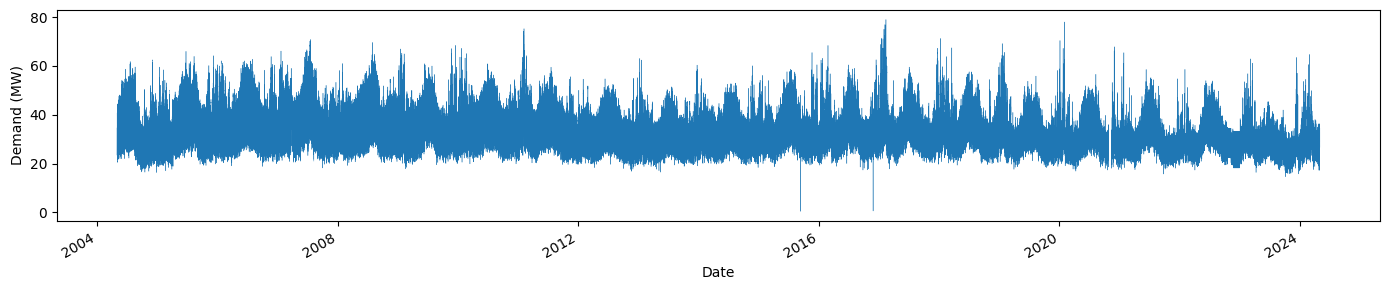

In [ ]:
# Time columns (all 96 intervals)
time_cols = [c for c in df.columns if ":" in str(c) and str(c)[0].isdigit()]

# Flatten into a continuous series
series = df[time_cols].values.flatten()

# Build a datetime axis: each day contributes 96 intervals ending at 00:15 … 24:00
dates = pd.to_datetime(df["Date"])
x = []
for d in dates:
    x.extend(pd.date_range(start=d, periods=96, freq="15min") + pd.Timedelta(minutes=15))
x = pd.DatetimeIndex(x)

print(f"Continuous series length: {len(series):,} intervals")
print(f"Time range: {x.min()} → {x.max()}")

# Plot
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(x, series, linewidth=0.3)
ax.set_xlabel("Date")
ax.set_ylabel("Demand (MW)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 1.4 What the missing data looks like

Before deciding how to impute, three questions define the scope of the problem:

1. **How many days are complete?** These are the days that can serve as candidates later.
2. **How are missing values distributed across days?** A day with one missing interval is trivially recoverable; a day with eighty is not.
3. **How large is each contiguous gap?** A day with two isolated missing values and a day with one contiguous gap of two intervals have the same count but very different implications for imputation.

Time columns detected: 96

Total days         : 7305
Complete days      :  6657  ( 91.1%)
Days with gaps     :   588  (  8.0%)
Empty days         :    60  (  0.8%)

Distribution of missing intervals per day:
  1 interval     :   467  ( 79.4%)
  2 intervals    :    18  (  3.1%)
  3 intervals    :    10  (  1.7%)
  4 or more      :    93  ( 15.8%)

Total gap blocks: 765
Mean length     : 12.14
Median length   : 1
Max length      : 96

Distribution of gap lengths:
  1         585  ( 76.5%)
  2          27  (  3.5%)
  3           5  (  0.7%)
  4–10       43  (  5.6%)
  11–30      10  (  1.3%)
  > 30       95  ( 12.4%)

Recoverability tiers:
  Complete (0)        :  6657  ( 91.1%)
  Minor (1–3)         :   495  (  6.8%)
  Moderate (4–30)     :    59  (  0.8%)
  Large (31–95)       :    34  (  0.5%)
  Empty (96)          :    60  (  0.8%)


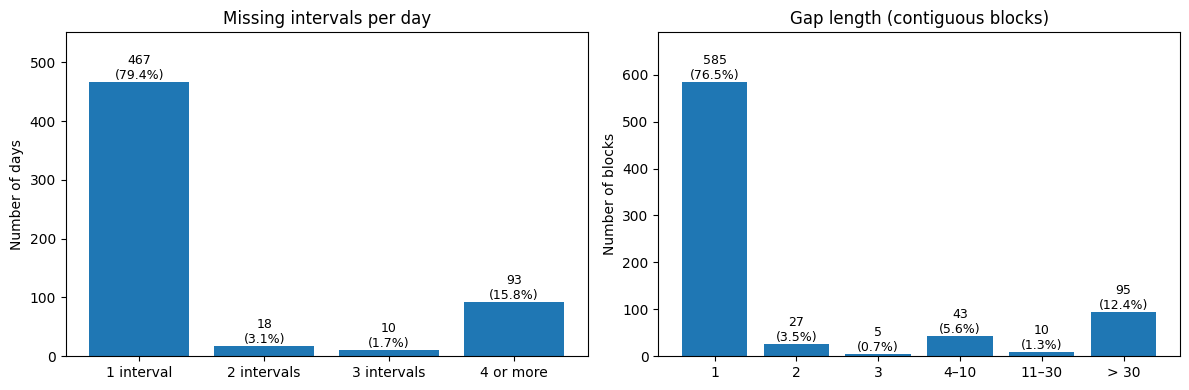

In [ ]:
# 1. Time columns
time_cols = [c for c in df.columns if ":" in str(c) and str(c)[0].isdigit()]
print(f"Time columns detected: {len(time_cols)}")

# 2. Missing intervals per day
missing_per_day = df[time_cols].isna().sum(axis=1)
total_days = len(df)

# 3. Classify each day
complete_days  = (missing_per_day == 0).sum()
days_with_gaps = ((missing_per_day > 0) & (missing_per_day < 96)).sum()
empty_days     = (missing_per_day == 96).sum()

def pct(n):
    return 100 * n / total_days

print(f"\nTotal days         : {total_days}")
print(f"Complete days      : {complete_days:>5}  ({pct(complete_days):5.1f}%)")
print(f"Days with gaps     : {days_with_gaps:>5}  ({pct(days_with_gaps):5.1f}%)")
print(f"Empty days         : {empty_days:>5}  ({pct(empty_days):5.1f}%)")

# 4. Distribution of missing intervals per day
counts_day = {
    "1 interval"  : (missing_per_day == 1).sum(),
    "2 intervals" : (missing_per_day == 2).sum(),
    "3 intervals" : (missing_per_day == 3).sum(),
    "4 or more"   : ((missing_per_day >= 4) & (missing_per_day < 96)).sum(),
}
gap_days_total = sum(counts_day.values())

print("\nDistribution of missing intervals per day:")
for label, n in counts_day.items():
    print(f"  {label:<15}: {n:>5}  ({100*n/gap_days_total:5.1f}%)")

# 5. Distribution of gap lengths (contiguous blocks)
def gap_lengths(row):
    is_nan = row.isna().values
    lengths, run = [], 0
    for v in is_nan:
        if v:
            run += 1
        elif run > 0:
            lengths.append(run)
            run = 0
    if run > 0:
        lengths.append(run)
    return lengths

all_lengths = []
for row in df[time_cols].itertuples(index=False):
    all_lengths.extend(gap_lengths(pd.Series(row)))
all_lengths = np.array(all_lengths)
blocks_total = len(all_lengths)

counts_block = {
    "1"      : (all_lengths == 1).sum(),
    "2"      : (all_lengths == 2).sum(),
    "3"      : (all_lengths == 3).sum(),
    "4–10"   : ((all_lengths >= 4)  & (all_lengths <= 10)).sum(),
    "11–30"  : ((all_lengths >= 11) & (all_lengths <= 30)).sum(),
    "> 30"   : (all_lengths > 30).sum(),
}

print(f"\nTotal gap blocks: {blocks_total}")
print(f"Mean length     : {all_lengths.mean():.2f}")
print(f"Median length   : {np.median(all_lengths):.0f}")
print(f"Max length      : {all_lengths.max()}")

print("\nDistribution of gap lengths:")
for label, n in counts_block.items():
    print(f"  {label:<6}  {n:>5}  ({100*n/blocks_total:5.1f}%)")

# 6. Recoverability tiers
tiers = {
    "Complete (0)"     : (missing_per_day == 0).sum(),
    "Minor (1–3)"      : ((missing_per_day >= 1) & (missing_per_day <= 3)).sum(),
    "Moderate (4–30)"  : ((missing_per_day >= 4) & (missing_per_day <= 30)).sum(),
    "Large (31–95)"    : ((missing_per_day >= 31) & (missing_per_day < 96)).sum(),
    "Empty (96)"       : (missing_per_day == 96).sum(),
}
print("\nRecoverability tiers:")
for label, n in tiers.items():
    print(f"  {label:<20}: {n:>5}  ({100*n/total_days:5.1f}%)")

# 7. Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(counts_day.keys(), counts_day.values())
axes[0].set_title("Missing intervals per day")
axes[0].set_ylabel("Number of days")
for i, v in enumerate(counts_day.values()):
    axes[0].text(i, v, f"{v}\n({100*v/gap_days_total:.1f}%)",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, max(counts_day.values()) * 1.18)

axes[1].bar(counts_block.keys(), counts_block.values())
axes[1].set_title("Gap length (contiguous blocks)")
axes[1].set_ylabel("Number of blocks")
for i, v in enumerate(counts_block.values()):
    axes[1].text(i, v, f"{v}\n({100*v/blocks_total:.1f}%)",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, max(counts_block.values()) * 1.18)

plt.tight_layout()
plt.show()

### 1.5 Single-point imputation and filtering to complete days

The analysis in 1.4 shows that 467 of the 588 gapped days have exactly one missing interval. Excluding them would discard information that is trivially recoverable; retaining them after a simple imputation increases the candidate pool by roughly 7%. Two options are available:

- **Option A — discard single-point gapped days.** The candidate pool contains only the 6,657 originally complete days.
- **Option B — impute single-point gaps.** Every contiguous gap of length 1 is filled with the average of its two neighbors.

In [ ]:
IMPUTE_SINGLE_POINT = True  # True: impute single-point gaps; False: discard those days

def impute_single_point_gaps(df, time_cols):
    """Fill each NaN that belongs to a contiguous block of length 1 with the neighbor average."""
    n_filled = 0
    for idx in df.index:
        row = df.loc[idx, time_cols].values.astype(float)
        is_nan = np.isnan(row)
        changed = False
        i = 0
        while i < len(row):
            if is_nan[i]:
                j = i
                while j < len(row) and is_nan[j]:
                    j += 1
                if j - i == 1:
                    if i > 0 and j < len(row):
                        row[i] = 0.5 * (row[i - 1] + row[j])
                    else:
                        row[i] = np.nanmean(row)
                    n_filled += 1
                    changed = True
                i = j
            else:
                i += 1
        if changed:
            df.loc[idx, time_cols] = row
    return n_filled

n_before = len(df)

if IMPUTE_SINGLE_POINT:
    n_filled = impute_single_point_gaps(df, time_cols)
    print(f"Single-point gaps imputed : {n_filled}")
else:
    print("Single-point imputation skipped")

# Keep only complete days
complete_mask = df[time_cols].notna().all(axis=1)
df = df[complete_mask].reset_index(drop=True)

print(f"\nDays before filter : {n_before:,}")
print(f"Days after filter  : {len(df):,}  ({n_before - len(df):,} removed)")
print(f"All complete now   : {df[time_cols].notna().all().all()}")

Single-point gaps imputed : 585

Days before filter : 7,305
Days after filter  : 7,147  (158 removed)
All complete now   : True


### 1.6 Normalization

Values are scaled to [0, 1] using the minimum and maximum of the complete days. The step is applied after the single-point imputation and filtering, so that the scaler parameters are not affected by days that were discarded for other reasons.

Because min-max scaling is an affine transformation with a positive slope, the ranking of candidates under any distance based on differences (Euclidean, DANLI) is preserved. The normalization therefore does not alter the conclusions of the comparison; it rescales the magnitude of the metrics so that they are comparable across substations.

In [ ]:
# Fit min-max scaler on the complete days (already filtered in the previous cell)
MIN_VAL = float(df[time_cols].min().min())
MAX_VAL = float(df[time_cols].max().max())
SPAN    = MAX_VAL - MIN_VAL + 1e-12

df[time_cols] = (df[time_cols] - MIN_VAL) / SPAN

print(f"Min-max fitted on {len(df):,} complete days")
print(f"Original range : [{MIN_VAL:.4f}, {MAX_VAL:.4f}]")
print(f"Normalized     : [{df[time_cols].min().min():.4f}, {df[time_cols].max().max():.4f}]")

Min-max fitted on 7,147 complete days
Original range : [0.4167, 78.9435]
Normalized     : [0.0000, 1.0000]


## 2. Synthetic gaps

The natural gaps documented in Section 1 do not provide ground-truth values, so they cannot serve as evaluation targets. This section introduces synthetic gaps under a controlled protocol: a fraction of the complete days is selected at random, each selected day receives exactly one contiguous gap, and the first and last intervals of the day are preserved as anchors. The gap length and start position are drawn uniformly from the admissible range.

Two DataFrames are saved to disk. `df_complete` holds the ground truth; `df_gaped` holds the same series with `NaN` at the gap positions. Their comparison provides the reference values required by the error metrics in later sections, and the CSV files allow the experiment to be resumed after a disconnection.

In [ ]:
# ============================================================
# Configuration
# ============================================================
GAPPED_DAYS_FRACTION = 0.40   # fraction of complete days that will receive a gap
GAP_DAY_SEED         = 26     # seed for selecting WHICH days get gaps
GAP_LENGTH_SEED      = 27     # seed for the gap length and position (independent)
USE_FIXED_SEEDS      = True   # True: reproducible; False: random each run

N = len(time_cols)
assert N >= 3, "Need at least 3 intervals to inject a gap while preserving anchors"

# ============================================================
# Seeds
# ============================================================
if USE_FIXED_SEEDS:
    rng_days = np.random.default_rng(GAP_DAY_SEED)
    rng_len  = np.random.default_rng(GAP_LENGTH_SEED)
else:
    rng_days = np.random.default_rng()
    rng_len  = np.random.default_rng()

# ============================================================
# Select gapped days
# ============================================================
n_days   = len(df)
n_gapped = int(round(GAPPED_DAYS_FRACTION * n_days))
gapped_idx = np.sort(rng_days.choice(n_days, size=n_gapped, replace=False))

# ============================================================
# Inject gaps (anchors 0 and N-1 preserved)
# ============================================================
df_complete = df.copy()
df_gaped    = df.copy()
gap_info    = {}   # day_index -> (start, end, length)

for idx in gapped_idx:
    L     = int(rng_len.integers(1, N - 1))       # length in [1, N-2]
    start = int(rng_len.integers(1, N - L))       # start in [1, N-1-L]
    end   = start + L - 1
    df_gaped.loc[idx, time_cols[start:end + 1]] = np.nan
    gap_info[idx] = (start, end, L)

# ============================================================
# Summary
# ============================================================
lengths = [v[2] for v in gap_info.values()]
print(f"Total days        : {n_days}")
print(f"Days with gap     : {n_gapped}  ({100*n_gapped/n_days:.1f}%)")
print(f"Days without gap  : {n_days - n_gapped}  ({100*(n_days-n_gapped)/n_days:.1f}%)")
print(f"Anchors preserved : positions 0 and {N-1}")
print(f"Gap length range  : {min(lengths)} – {max(lengths)} intervals")
print(f"Mean gap length   : {np.mean(lengths):.1f} intervals")
print(f"Median gap length : {np.median(lengths):.0f} intervals")

# ============================================================
# Save
# ============================================================
df_complete.to_csv("df_complete.csv", index=False)
df_gaped.to_csv("df_gaped.csv", index=False)
print("\nSaved: df_complete.csv, df_gaped.csv")

Total days        : 7147
Days with gap     : 2859  (40.0%)
Days without gap  : 4288  (60.0%)
Anchors preserved : positions 0 and 95
Gap length range  : 1 – 94 intervals
Mean gap length   : 47.2 intervals
Median gap length : 48 intervals

Saved: df_complete.csv, df_gaped.csv


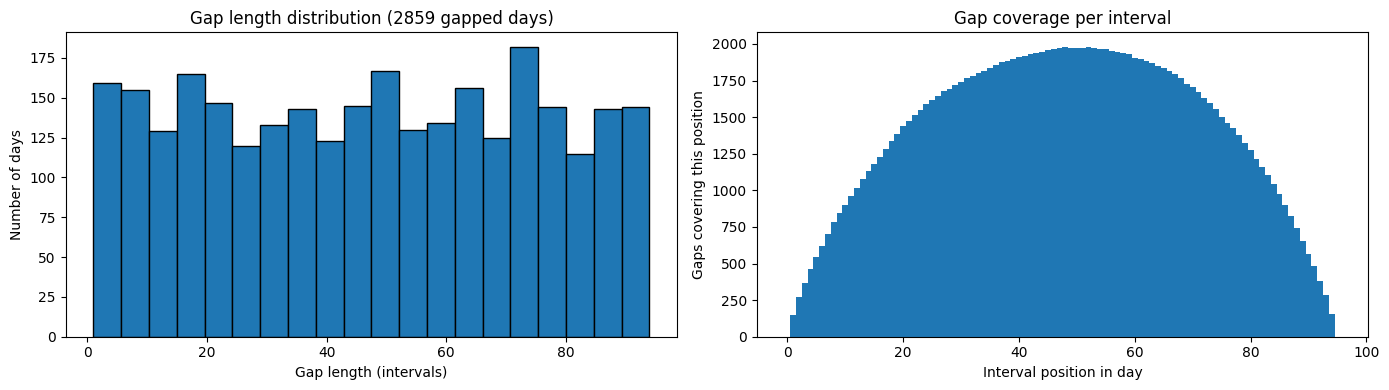

In [ ]:
# Gap distribution

lengths = [v[2] for v in gap_info.values()]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# (a) Gap length distribution
axes[0].hist(lengths, bins=20, edgecolor="black")
axes[0].set_xlabel("Gap length (intervals)")
axes[0].set_ylabel("Number of days")
axes[0].set_title(f"Gap length distribution ({n_gapped} gapped days)")

# (b) Coverage: how many gaps cover each interval position
coverage = np.zeros(N)
for idx in gapped_idx:
    start, end, _ = gap_info[idx]
    coverage[start:end + 1] += 1
axes[1].bar(range(N), coverage, width=1.0)
axes[1].set_xlabel("Interval position in day")
axes[1].set_ylabel("Gaps covering this position")
axes[1].set_title("Gap coverage per interval")

plt.tight_layout()
plt.show()

## 3. Traditional (simple) imputations

Three traditional imputation methods are applied to the same `df_gaped`, providing a reference against which the cumulative-profile methods are compared in later sections. All three compute their statistics from `df_complete` only; the gapped days are never used to estimate the values that will fill them.

- **Linear** — connects the last observed value before the gap with the first observed value after it.
- **Global average** — fills every missing interval with a single constant: the mean of all values across all complete days.
- **Average point** — fills each missing position with the mean of that position across all complete days, so the fill profile follows the average daily shape.

In [ ]:
DATA_GAPED    = "df_gaped.csv"
DATA_COMPLETE = "df_complete.csv"

df_gaped    = pd.read_csv(DATA_GAPED)
df_complete = pd.read_csv(DATA_COMPLETE)

time_cols = [c for c in df_gaped.columns if ":" in str(c) and str(c)[0].isdigit()]
N = len(time_cols)

def extract_gaps(df_gaped, time_cols):
    """Return dict day_index -> (start, end) for every day that contains NaN."""
    gaps = {}
    for idx in df_gaped.index:
        is_nan = df_gaped.loc[idx, time_cols].isna().values
        if not is_nan.any():
            continue
        pos = np.where(is_nan)[0]
        gaps[idx] = (int(pos.min()), int(pos.max()))
    return gaps

gaps = extract_gaps(df_gaped, time_cols)

print(f"df_gaped    : {len(df_gaped):,} days  ({len(gaps):,} with gaps)")
print(f"df_complete : {len(df_complete):,} days")
print(f"Intervals   : {N} per day")

df_gaped    : 7,147 days  (2,859 with gaps)
df_complete : 7,147 days
Intervals   : 96 per day


## 3.1 Linear imputation

In [ ]:
def impute_linear(df_gaped, gaps, time_cols):
    """Interpolate between the boundary values on each side of the gap."""
    df_out = df_gaped.copy()
    for idx, (start, end) in gaps.items():
        left  = df_out.loc[idx, time_cols[start - 1]]
        right = df_out.loc[idx, time_cols[end + 1]]
        L = end - start + 1
        df_out.loc[idx, time_cols[start:end + 1]] = np.linspace(left, right, L + 2)[1:-1]
    return df_out

df_linear = impute_linear(df_gaped, gaps, time_cols)
df_linear.to_csv("trad_linear.csv", index=False)
print("Saved: trad_linear.csv")

Saved: trad_linear.csv


## 3.2 Global average

In [ ]:
global_average = float(df_complete[time_cols].values.flatten().mean())

df_global = df_gaped.copy()
for c in time_cols:
    df_global[c] = df_global[c].fillna(global_average)

df_global.to_csv("trad_global_average.csv", index=False)
print(f"Global average constant: {global_average:.4f}")
print("Saved: trad_global_average.csv")

Global average constant: 0.4312
Saved: trad_global_average.csv


## 3.3 Average Point

In [ ]:
position_means = df_complete[time_cols].mean(axis=0)   # one value per interval

df_point = df_gaped.copy()
for i, c in enumerate(time_cols):
    df_point[c] = df_point[c].fillna(position_means.iloc[i])

df_point.to_csv("trad_average_point.csv", index=False)
print("Saved: trad_average_point.csv")

Saved: trad_average_point.csv


## 3.4 Sample plots

Chosen day : 2021-10-02
Gap        : positions 18–87  (70 intervals)
Available gap lengths: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94]


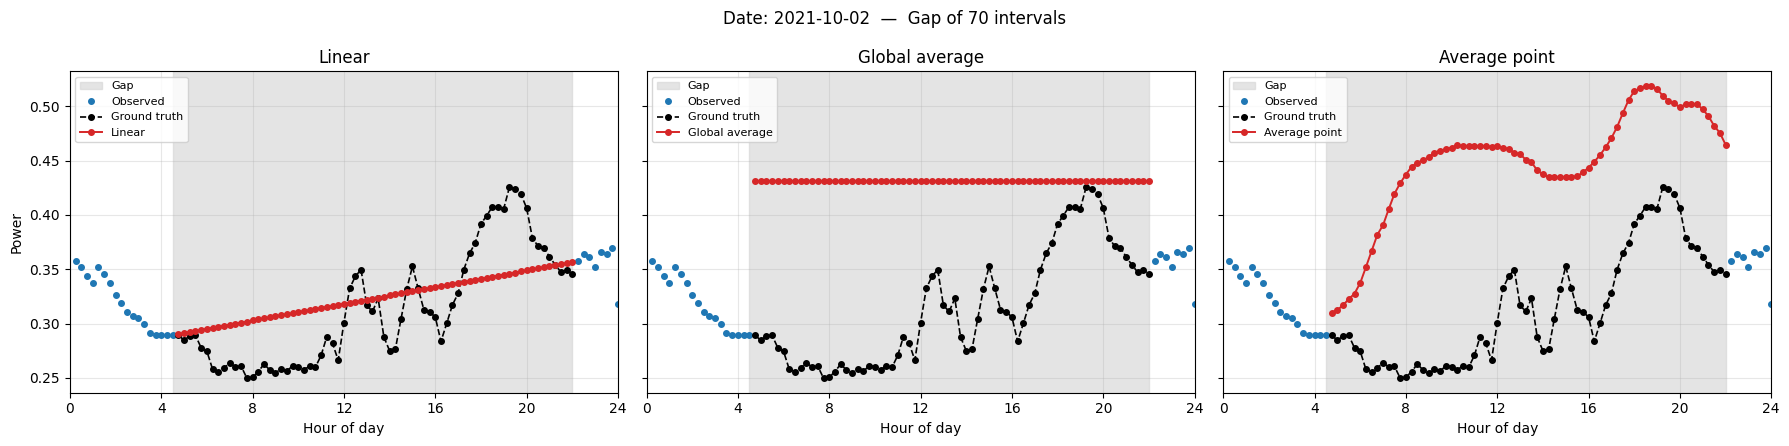

In [ ]:
GAP_LENGTH_TO_PLOT = 70   # set to any length present in the synthetic gaps

# --- select a day with that gap length (fallback to nearest if absent) ----
gap_lengths = {idx: end - start + 1 for idx, (start, end) in gaps.items()}
available = sorted(set(gap_lengths.values()))

if GAP_LENGTH_TO_PLOT in available:
    chosen_length = GAP_LENGTH_TO_PLOT
else:
    chosen_length = min(available, key=lambda L: abs(L - GAP_LENGTH_TO_PLOT))
    print(f"[info] No gaps of length {GAP_LENGTH_TO_PLOT}; using nearest: {chosen_length}")

candidates = [idx for idx, L in gap_lengths.items() if L == chosen_length]
chosen_idx = int(np.random.default_rng(0).choice(candidates))

gap_start, gap_end = gaps[chosen_idx]
gap_length = gap_end - gap_start + 1
date_str = str(df_gaped.loc[chosen_idx, "Date"])

print(f"Chosen day : {date_str}")
print(f"Gap        : positions {gap_start}–{gap_end}  ({gap_length} intervals)")
print(f"Available gap lengths: {available}")

hours = (np.arange(N) + 1) * (24 / N)
shade_left  = gap_start * (24 / N)
shade_right = (gap_end + 1) * (24 / N)

obs_mask = np.ones(N, dtype=bool)
obs_mask[gap_start:gap_end + 1] = False

truth = df_complete.loc[chosen_idx, time_cols].values.astype(float)

methods = {
    "Linear":         df_linear,
    "Global average": df_global,
    "Average point":  df_point,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (name, df_imp) in zip(axes, methods.items()):
    imputed = df_imp.loc[chosen_idx, time_cols].values.astype(float)

    ax.axvspan(shade_left, shade_right, color="lightgray", alpha=0.6, label="Gap")
    ax.plot(hours[obs_mask], truth[obs_mask], "o",
            color="tab:blue", markersize=4, label="Observed")
    ax.plot(hours[~obs_mask], truth[~obs_mask], "o--",
            color="black", markersize=4, linewidth=1.2, label="Ground truth")
    ax.plot(hours[~obs_mask], imputed[~obs_mask], "o-",
            color="tab:red", markersize=4, linewidth=1.4, label=name)

    ax.set_xlim(0, 24)
    ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("Hour of day")
    ax.set_title(name)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel("Power")
fig.suptitle(f"Date: {date_str}  —  Gap of {gap_length} intervals", fontsize=12)
plt.tight_layout()
plt.show()

## 4. Euclidean copy-paste

The Euclidean criterion compares a gapped day $\mathbf{g}$ with each complete candidate $\mathbf{c}$ of the same weekday $w$ over the observed indices $T_{\text{obs}}$:

$$
d_{\text{EUC}}(\mathbf{g}, \mathbf{c}) = \sqrt{\sum_{t \in T_{\text{obs}}} (g_t - c_t)^2}
$$

The candidate minimizing $d_{\text{EUC}}$ is copied into the gap. Conditioning on weekday restricts the search to days with the same calendar context, but it does not enforce shape similarity beyond what the observed intervals already provide. The criterion is point-wise: a candidate that matches the observed segments well but implies a different total energy inside the gap can still be selected.

In [ ]:
# Candidate pool and impute

# Reload in case the kernel was restarted
df_gaped    = pd.read_csv("df_gaped.csv")
df_complete = pd.read_csv("df_complete.csv")

time_cols = [c for c in df_gaped.columns if ":" in str(c) and str(c)[0].isdigit()]
N = len(time_cols)

gaps = {}
for idx in df_gaped.index:
    is_nan = df_gaped.loc[idx, time_cols].isna().values
    if is_nan.any():
        pos = np.where(is_nan)[0]
        gaps[idx] = (int(pos.min()), int(pos.max()))

# Weekday for each day
weekday_all = pd.to_datetime(df_gaped["Date"]).dt.day_name()

# Candidate pool: complete days only, grouped by weekday
gapped_set = set(gaps.keys())
candidates_by_weekday = {}
for wd in weekday_all.unique():
    mask = (weekday_all == wd) & (~df_gaped.index.isin(gapped_set))
    idxs = df_gaped.index[mask].tolist()
    candidates_by_weekday[wd] = np.stack([
        df_complete.loc[i, time_cols].values.astype(float) for i in idxs
    ])
    print(f"{wd:<10}: {len(idxs)} candidates")

# Apply Euclidean imputation
df_euclidean = df_gaped.copy()
for idx, (start, end) in gaps.items():
    wd  = weekday_all.loc[idx]
    g   = df_gaped.loc[idx, time_cols].values.astype(float)
    obs = ~np.isnan(g)
    cands = candidates_by_weekday[wd]
    diffs = cands[:, obs] - g[obs]
    dist  = np.sqrt((diffs ** 2).sum(axis=1))
    best  = int(np.argmin(dist))
    df_euclidean.loc[idx, time_cols[start:end + 1]] = cands[best, start:end + 1]

df_euclidean.to_csv("phys_euclidean.csv", index=False)
print(f"\nImputed {len(gaps)} gapped days")
print("Saved: phys_euclidean.csv")

Saturday  : 625 candidates
Sunday    : 611 candidates
Monday    : 619 candidates
Tuesday   : 652 candidates
Wednesday : 572 candidates
Thursday  : 597 candidates
Friday    : 612 candidates

Imputed 2859 gapped days
Saved: phys_euclidean.csv


### 4.1 Example reconstructions

Three days are selected at the gap lengths specified in `GAP_LENGTHS_TO_PLOT`. For each day the figure shows the observed intervals, the ground truth inside the gap, and the values produced by the Euclidean copy-paste criterion.

Available gap lengths: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94]


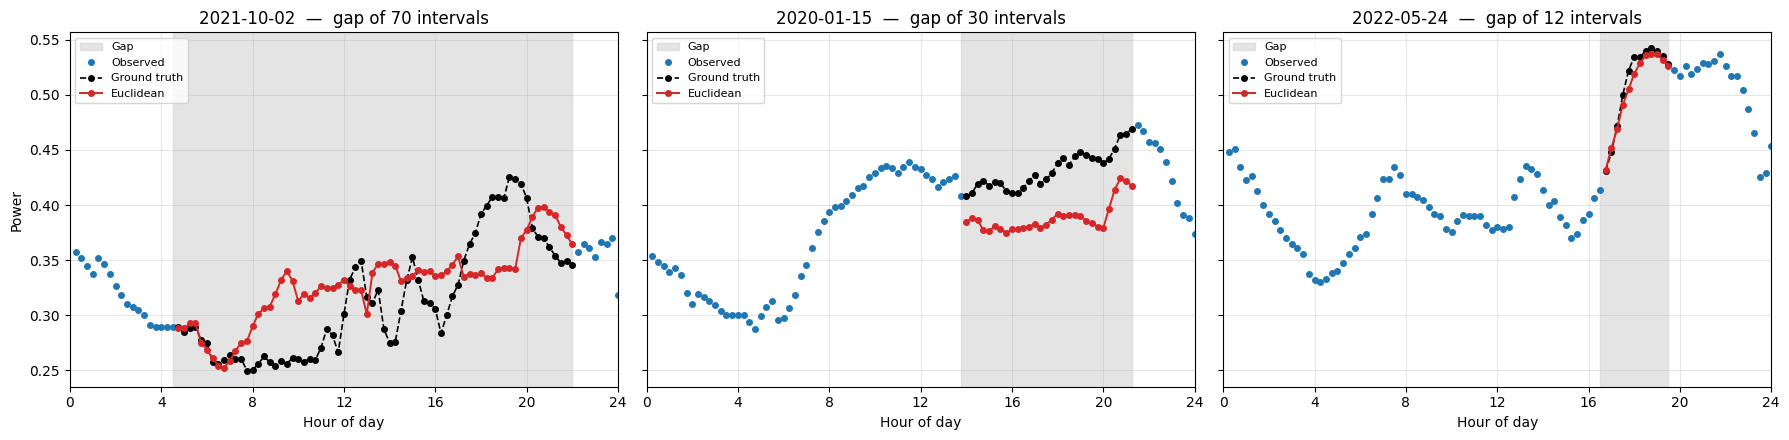

In [ ]:
# Examples

GAP_LENGTHS_TO_PLOT = [70, 30, 12]   # one gap length per subplot

gap_lengths = {idx: end - start + 1 for idx, (start, end) in gaps.items()}
available   = sorted(set(gap_lengths.values()))

chosen = []
for target in GAP_LENGTHS_TO_PLOT:
    length = target if target in available else min(available, key=lambda L: abs(L - target))
    cands  = [idx for idx, L in gap_lengths.items() if L == length]
    pick   = int(np.random.default_rng(0).choice(cands))
    chosen.append((pick, length))

print(f"Available gap lengths: {available}")

hours = (np.arange(N) + 1) * (24 / N)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (idx, length) in zip(axes, chosen):
    start, end = gaps[idx]
    date_str   = str(df_gaped.loc[idx, "Date"])

    shade_left  = start * (24 / N)
    shade_right = (end + 1) * (24 / N)

    obs_mask = np.ones(N, dtype=bool)
    obs_mask[start:end + 1] = False

    truth   = df_complete.loc[idx, time_cols].values.astype(float)
    imputed = df_euclidean.loc[idx, time_cols].values.astype(float)

    ax.axvspan(shade_left, shade_right, color="lightgray", alpha=0.6, label="Gap")
    ax.plot(hours[obs_mask], truth[obs_mask], "o",
            color="tab:blue", markersize=4, label="Observed")
    ax.plot(hours[~obs_mask], truth[~obs_mask], "o--",
            color="black", markersize=4, linewidth=1.2, label="Ground truth")
    ax.plot(hours[~obs_mask], imputed[~obs_mask], "o-",
            color="tab:red", markersize=4, linewidth=1.4, label="Euclidean")

    ax.set_xlim(0, 24)
    ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("Hour of day")
    ax.set_title(f"{date_str}  —  gap of {length} intervals")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel("Power")
plt.tight_layout()
plt.show()

### 4.2 Weighted combination of the K nearest candidates

The copy-paste criterion selects a single candidate. Multiple candidates often yield comparable distances, and combining them reduces the influence of any individual match. The extension builds a synthetic reconstruction from the top-$K$ candidates with the smallest Euclidean distances,

$$
\hat{y}_t = \sum_{k=1}^{K} w_k \, c_{(k), t}, \qquad
w_k = \frac{(d_{\text{EUC}}(\mathbf{g}, \mathbf{c}_{(k)}) + \varepsilon)^{-1}}{\sum_{j=1}^{K} (d_{\text{EUC}}(\mathbf{g}, \mathbf{c}_{(j)}) + \varepsilon)^{-1}},
$$

where $\mathbf{c}_{(k)}$ denotes the $k$-th nearest candidate and $\varepsilon > 0$ prevents division by zero when a candidate matches the observed intervals exactly. Because $w_k \geq 0$ and $\sum_k w_k = 1$, the reconstruction at each interval lies within the convex hull of the $K$ candidate values, so the method does not extrapolate beyond the values present in the pool. The original copy-paste criterion is the particular case $K = 1$.

In [ ]:
K_EUCLIDEAN = 5       # number of neighbors
EPS_WEIGHTS = 1e-10   # small constant to avoid division by zero

# --- ensure the input data is loaded (safe if the kernel was restarted) ----
df_gaped    = pd.read_csv("df_gaped.csv")
df_complete = pd.read_csv("df_complete.csv")

time_cols = [c for c in df_gaped.columns if ":" in str(c) and str(c)[0].isdigit()]
N = len(time_cols)

gaps = {}
for idx in df_gaped.index:
    is_nan = df_gaped.loc[idx, time_cols].isna().values
    if is_nan.any():
        pos = np.where(is_nan)[0]
        gaps[idx] = (int(pos.min()), int(pos.max()))

weekday_all  = pd.to_datetime(df_gaped["Date"]).dt.day_name()
gapped_set   = set(gaps.keys())

# Candidate pool, grouped by weekday (complete days only)
candidates_by_weekday = {}
for wd in weekday_all.unique():
    mask = (weekday_all == wd) & (~df_gaped.index.isin(gapped_set))
    idxs = df_gaped.index[mask].tolist()
    candidates_by_weekday[wd] = np.stack([
        df_complete.loc[i, time_cols].values.astype(float) for i in idxs
    ])

# --- Euclidean K-NN imputation --------------------------------------------
df_euclidean_knn = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd  = weekday_all.loc[idx]
    g   = df_gaped.loc[idx, time_cols].values.astype(float)
    obs = ~np.isnan(g)
    cands = candidates_by_weekday[wd]

    dist   = np.sqrt(((cands[:, obs] - g[obs]) ** 2).sum(axis=1))
    order  = np.argsort(dist)
    k_actual = min(K_EUCLIDEAN, len(order))
    top  = order[:k_actual]
    d_k  = dist[top]
    w    = 1.0 / (d_k + EPS_WEIGHTS)
    w    = w / w.sum()

    df_euclidean_knn.loc[idx, time_cols[start:end + 1]] = np.average(
        cands[top, start:end + 1], axis=0, weights=w
    )

df_euclidean_knn.to_csv("phys_euclidean_knn.csv", index=False)
print(f"K used        : {K_EUCLIDEAN}")
print(f"Imputed days  : {len(gaps)}")
print("Saved: phys_euclidean_knn.csv")

K used        : 5
Imputed days  : 2859
Saved: phys_euclidean_knn.csv


Available gap lengths: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94]
K used: 5


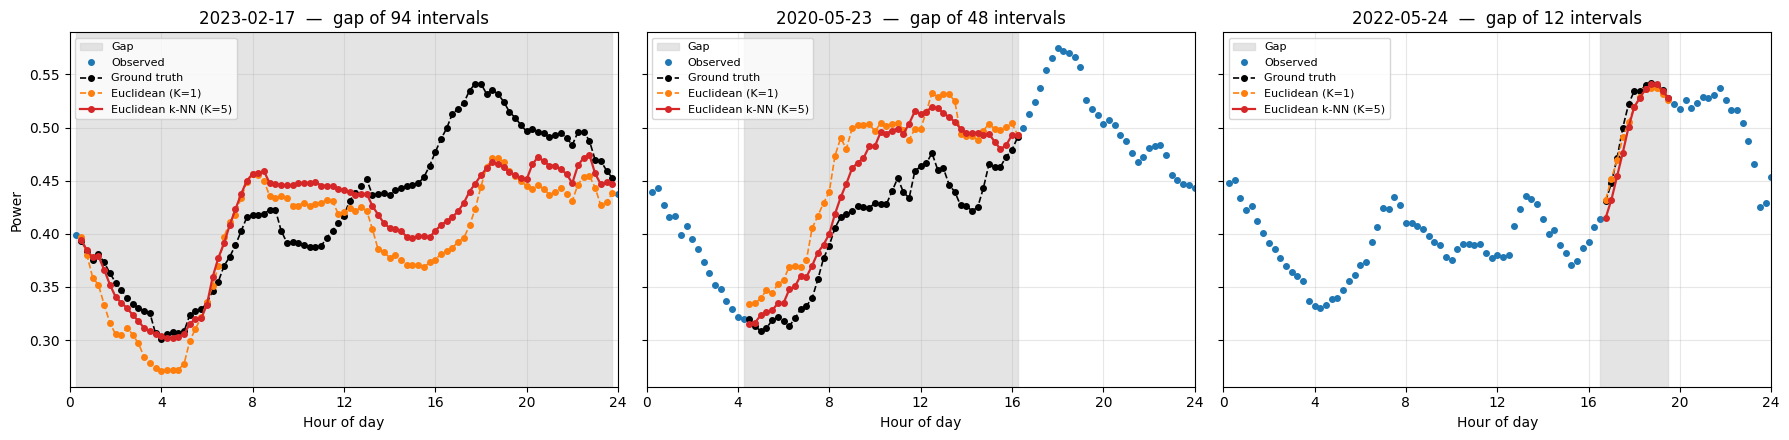

In [ ]:
GAP_LENGTHS_TO_PLOT = [94, 48, 12]

gap_lengths = {idx: end - start + 1 for idx, (start, end) in gaps.items()}
available   = sorted(set(gap_lengths.values()))

chosen = []
for target in GAP_LENGTHS_TO_PLOT:
    length = target if target in available else min(available, key=lambda L: abs(L - target))
    cands  = [idx for idx, L in gap_lengths.items() if L == length]
    pick   = int(np.random.default_rng(0).choice(cands))
    chosen.append((pick, length))

print(f"Available gap lengths: {available}")
print(f"K used: {K_EUCLIDEAN}")

hours = (np.arange(N) + 1) * (24 / N)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (idx, length) in zip(axes, chosen):
    start, end = gaps[idx]
    date_str   = str(df_gaped.loc[idx, "Date"])

    shade_left  = start * (24 / N)
    shade_right = (end + 1) * (24 / N)

    obs_mask = np.ones(N, dtype=bool)
    obs_mask[start:end + 1] = False

    truth    = df_complete.loc[idx, time_cols].values.astype(float)
    k1       = df_euclidean.loc[idx, time_cols].values.astype(float)
    knn      = df_euclidean_knn.loc[idx, time_cols].values.astype(float)

    ax.axvspan(shade_left, shade_right, color="lightgray", alpha=0.6, label="Gap")
    ax.plot(hours[obs_mask], truth[obs_mask], "o",
            color="tab:blue", markersize=4, label="Observed")
    ax.plot(hours[~obs_mask], truth[~obs_mask], "o--",
            color="black", markersize=4, linewidth=1.2, label="Ground truth")
    ax.plot(hours[~obs_mask], k1[~obs_mask], "o--",
            color="tab:orange", markersize=4, linewidth=1.2,
            label="Euclidean (K=1)")
    ax.plot(hours[~obs_mask], knn[~obs_mask], "o-",
            color="tab:red", markersize=4, linewidth=1.6,
            label=f"Euclidean k-NN (K={K_EUCLIDEAN})")

    ax.set_xlim(0, 24)
    ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("Hour of day")
    ax.set_title(f"{date_str}  —  gap of {length} intervals")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel("Power")
plt.tight_layout()
plt.show()

## 5. DANLI

DANLI compares a gapped day $\mathbf{g}$ with each complete candidate $\mathbf{c}$ of the same weekday through the cumulative quantities observed on both sides of the gap. Three distance components are defined:

$$
d_{\text{fwd}} = \bigl(C^{\text{fwd}}_g - C^{\text{fwd}}_c\bigr)^2, \qquad
d_{\text{bwd}} = \bigl(C^{\text{bwd}}_g - C^{\text{bwd}}_c\bigr)^2, \qquad
d_{\text{total}} = \bigl(Q_c - \bar{Q}_w\bigr)^2,
$$

where $C^{\text{fwd}}_g = \sum_{t<s} g_t$ and $C^{\text{bwd}}_g = \sum_{t>e} g_t$ are the cumulative quantities before and after the gap, $Q_c = \sum_t c_t$ is the candidate's total daily energy, and

$$
\bar{Q}_w = \frac{1}{|\mathcal{D}^{(w)}_{\text{complete}}|} \sum_{\mathbf{c} \in \mathcal{D}^{(w)}_{\text{complete}}} Q_c
$$

is the mean total daily energy of the complete candidates in the same weekday context $w$.

The full DANLI distance is

$$
d_{\text{DANLI}} = \sqrt{d_{\text{fwd}} + d_{\text{bwd}} + \lambda \, d_{\text{total}}}, \qquad \lambda \geq 0.
$$

Two regimes are evaluated in this tutorial:

- **$\lambda = 0$** — the total-energy term is dropped. The criterion ranks candidates purely by their cumulative profiles before and after the gap.
- **$\lambda = 1$** — the total-energy term contributes with unit weight. Candidates whose daily energy departs from the historical weekday average are penalized, even if their boundary profiles match.

The particular case $\lambda = 0$ isolates the profile-based component of the criterion; $\lambda = 1$ tests whether the mean-energy regularizer adds value beyond that.

In [ ]:
# --- ensure input data is loaded -------------------------------------------
df_gaped    = pd.read_csv("df_gaped.csv")
df_complete = pd.read_csv("df_complete.csv")

time_cols = [c for c in df_gaped.columns if ":" in str(c) and str(c)[0].isdigit()]
N = len(time_cols)

gaps = {}
for idx in df_gaped.index:
    is_nan = df_gaped.loc[idx, time_cols].isna().values
    if is_nan.any():
        pos = np.where(is_nan)[0]
        gaps[idx] = (int(pos.min()), int(pos.max()))

weekday_all = pd.to_datetime(df_gaped["Date"]).dt.day_name()
gapped_set  = set(gaps.keys())

# --- candidate pool with precomputed cumulative profiles -------------------
def build_candidate_pool(df_gaped, df_complete, time_cols, weekday_all, gapped_set):
    """Return per-weekday dict of stacked arrays: values, prefix, suffix, total, Qbar."""
    pool = {}
    for wd in weekday_all.unique():
        mask = (weekday_all == wd) & (~df_gaped.index.isin(gapped_set))
        idxs = df_gaped.index[mask].tolist()
        vals = np.stack([df_complete.loc[i, time_cols].values.astype(float) for i in idxs])
        pool[wd] = {
            "values": vals,
            "prefix": np.cumsum(vals, axis=1),
            "suffix": np.cumsum(vals[:, ::-1], axis=1)[:, ::-1],
            "total":  vals.sum(axis=1),
            "Qbar":   float(vals.sum(axis=1).mean()),
        }
    return pool

pool = build_candidate_pool(df_gaped, df_complete, time_cols, weekday_all, gapped_set)

# --- DANLI distance (vectorized) ------------------------------------------
def danli_distances(y, start, end, pool_wd, lam):
    """Distance from gapped day y (with gap [start, end]) to all candidates in pool_wd."""
    C_fwd_gap = float(np.nansum(y[:start]))
    C_bwd_gap = float(np.nansum(y[end + 1:]))

    C_fwd_cmp = pool_wd["prefix"][:, start - 1] if start > 0 else np.zeros(len(pool_wd["total"]))
    C_bwd_cmp = pool_wd["suffix"][:, end + 1] if end < N - 1 else np.zeros(len(pool_wd["total"]))

    d_fwd = (C_fwd_gap - C_fwd_cmp) ** 2
    d_bwd = (C_bwd_gap - C_bwd_cmp) ** 2
    d_tot = (pool_wd["total"] - pool_wd["Qbar"]) ** 2
    return np.sqrt(d_fwd + d_bwd + lam * d_tot)

# --- DANLI λ=0, K=1 -------------------------------------------------------
LAMBDA = 0.0
df_danli_l0 = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd = weekday_all.loc[idx]
    y  = df_gaped.loc[idx, time_cols].values.astype(float)
    pw = pool[wd]
    dist = danli_distances(y, start, end, pw, LAMBDA)
    best = int(np.argmin(dist))
    df_danli_l0.loc[idx, time_cols[start:end + 1]] = pw["values"][best, start:end + 1]

df_danli_l0.to_csv("phys_danli_l0.csv", index=False)
print(f"λ = {LAMBDA}, K = 1")
print(f"Imputed days: {len(gaps)}")
print("Saved: phys_danli_l0.csv")

λ = 0.0, K = 1
Imputed days: 2859
Saved: phys_danli_l0.csv


In [ ]:
LAMBDA = 1.0
df_danli_l1 = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd = weekday_all.loc[idx]
    y  = df_gaped.loc[idx, time_cols].values.astype(float)
    pw = pool[wd]
    dist = danli_distances(y, start, end, pw, LAMBDA)
    best = int(np.argmin(dist))
    df_danli_l1.loc[idx, time_cols[start:end + 1]] = pw["values"][best, start:end + 1]

df_danli_l1.to_csv("phys_danli_l1.csv", index=False)
print(f"λ = {LAMBDA}, K = 1")
print(f"Imputed days: {len(gaps)}")
print("Saved: phys_danli_l1.csv")

λ = 1.0, K = 1
Imputed days: 2859
Saved: phys_danli_l1.csv


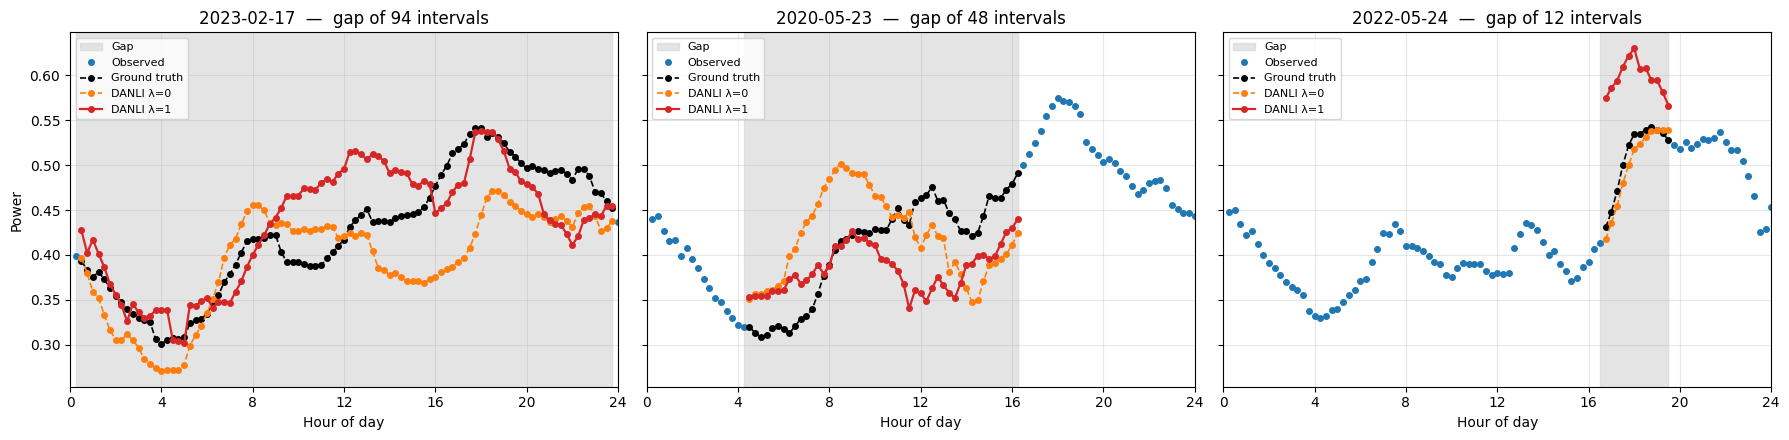

In [ ]:
GAP_LENGTHS_TO_PLOT = [94, 48, 12]

gap_lengths = {idx: end - start + 1 for idx, (start, end) in gaps.items()}
available   = sorted(set(gap_lengths.values()))

chosen = []
for target in GAP_LENGTHS_TO_PLOT:
    length = target if target in available else min(available, key=lambda L: abs(L - target))
    cands  = [idx for idx, L in gap_lengths.items() if L == length]
    pick   = int(np.random.default_rng(0).choice(cands))
    chosen.append((pick, length))

hours = (np.arange(N) + 1) * (24 / N)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (idx, length) in zip(axes, chosen):
    start, end = gaps[idx]
    date_str   = str(df_gaped.loc[idx, "Date"])
    shade_l, shade_r = start * (24 / N), (end + 1) * (24 / N)

    obs_mask = np.ones(N, dtype=bool); obs_mask[start:end + 1] = False

    truth = df_complete.loc[idx, time_cols].values.astype(float)
    l0    = df_danli_l0.loc[idx, time_cols].values.astype(float)
    l1    = df_danli_l1.loc[idx, time_cols].values.astype(float)

    ax.axvspan(shade_l, shade_r, color="lightgray", alpha=0.6, label="Gap")
    ax.plot(hours[obs_mask], truth[obs_mask], "o", color="tab:blue", markersize=4, label="Observed")
    ax.plot(hours[~obs_mask], truth[~obs_mask], "o--", color="black", markersize=4, linewidth=1.2, label="Ground truth")
    ax.plot(hours[~obs_mask], l0[~obs_mask], "o--", color="tab:orange", markersize=4, linewidth=1.2, label="DANLI λ=0")
    ax.plot(hours[~obs_mask], l1[~obs_mask], "o-",  color="tab:red",    markersize=4, linewidth=1.6, label="DANLI λ=1")

    ax.set_xlim(0, 24); ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("Hour of day")
    ax.set_title(f"{date_str}  —  gap of {length} intervals")
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel("Power")
plt.tight_layout()
plt.show()

### 5.1 Weighted combination of the K nearest candidates

The $K$-neighbor extension follows the same construction as in Section 4.5, replacing the Euclidean distance with $d_{\text{DANLI}}$:

$$
\hat{y}_t = \sum_{k=1}^{K} w_k \, c_{(k), t}, \qquad
w_k = \frac{(d_{\text{DANLI}}(\mathbf{g}, \mathbf{c}_{(k)}) + \varepsilon)^{-1}}{\sum_{j=1}^{K} (d_{\text{DANLI}}(\mathbf{g}, \mathbf{c}_{(j)}) + \varepsilon)^{-1}}.
$$

The parameter $\lambda$ and the number of neighbors $K$ act on orthogonal axes: $\lambda$ controls which candidates are considered good matches, while $K$ controls how many of them are blended. The four combinations ($\lambda \in \{0, 1\} \times K \in \{1, K_{\max}\}$) are evaluated separately so that each parameter's contribution can be isolated.

In [ ]:
K_DANLI    = 5
EPS_WEIGHTS = 1e-10

df_danli_l0_knn = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd = weekday_all.loc[idx]
    y  = df_gaped.loc[idx, time_cols].values.astype(float)
    pw = pool[wd]

    dist = danli_distances(y, start, end, pw, lam=0.0)
    order = np.argsort(dist)
    k_actual = min(K_DANLI, len(order))
    top = order[:k_actual]
    w = 1.0 / (dist[top] + EPS_WEIGHTS)
    w = w / w.sum()

    df_danli_l0_knn.loc[idx, time_cols[start:end + 1]] = np.average(
        pw["values"][top, start:end + 1], axis=0, weights=w
    )

df_danli_l0_knn.to_csv("phys_danli_l0_knn.csv", index=False)
print(f"λ = 0.0, K = {K_DANLI}")
print(f"Imputed days: {len(gaps)}")
print("Saved: phys_danli_l0_knn.csv")

λ = 0.0, K = 5
Imputed days: 2859
Saved: phys_danli_l0_knn.csv


In [ ]:
df_danli_l1_knn = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd = weekday_all.loc[idx]
    y  = df_gaped.loc[idx, time_cols].values.astype(float)
    pw = pool[wd]

    dist = danli_distances(y, start, end, pw, lam=1.0)
    order = np.argsort(dist)
    k_actual = min(K_DANLI, len(order))
    top = order[:k_actual]
    w = 1.0 / (dist[top] + EPS_WEIGHTS)
    w = w / w.sum()

    df_danli_l1_knn.loc[idx, time_cols[start:end + 1]] = np.average(
        pw["values"][top, start:end + 1], axis=0, weights=w
    )

df_danli_l1_knn.to_csv("phys_danli_l1_knn.csv", index=False)
print(f"λ = 1.0, K = {K_DANLI}")
print(f"Imputed days: {len(gaps)}")
print("Saved: phys_danli_l1_knn.csv")

λ = 1.0, K = 5
Imputed days: 2859
Saved: phys_danli_l1_knn.csv


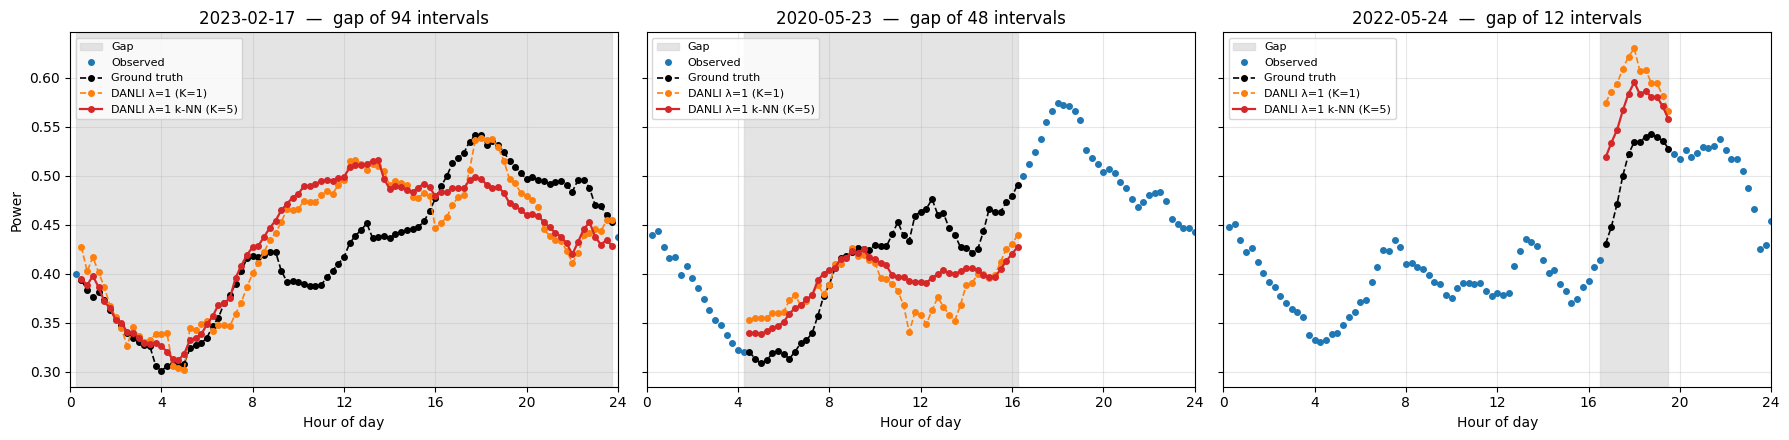

In [ ]:
GAP_LENGTHS_TO_PLOT = [94, 48, 12]

chosen = []
for target in GAP_LENGTHS_TO_PLOT:
    length = target if target in available else min(available, key=lambda L: abs(L - target))
    cands  = [idx for idx, L in gap_lengths.items() if L == length]
    pick   = int(np.random.default_rng(0).choice(cands))
    chosen.append((pick, length))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (idx, length) in zip(axes, chosen):
    start, end = gaps[idx]
    date_str   = str(df_gaped.loc[idx, "Date"])
    shade_l, shade_r = start * (24 / N), (end + 1) * (24 / N)

    obs_mask = np.ones(N, dtype=bool); obs_mask[start:end + 1] = False

    truth = df_complete.loc[idx, time_cols].values.astype(float)
    k1    = df_danli_l1.loc[idx, time_cols].values.astype(float)
    knn   = df_danli_l1_knn.loc[idx, time_cols].values.astype(float)

    ax.axvspan(shade_l, shade_r, color="lightgray", alpha=0.6, label="Gap")
    ax.plot(hours[obs_mask], truth[obs_mask], "o", color="tab:blue", markersize=4, label="Observed")
    ax.plot(hours[~obs_mask], truth[~obs_mask], "o--", color="black", markersize=4, linewidth=1.2, label="Ground truth")
    ax.plot(hours[~obs_mask], k1[~obs_mask], "o--", color="tab:orange", markersize=4, linewidth=1.2, label="DANLI λ=1 (K=1)")
    ax.plot(hours[~obs_mask], knn[~obs_mask], "o-",  color="tab:red",    markersize=4, linewidth=1.6, label=f"DANLI λ=1 k-NN (K={K_DANLI})")

    ax.set_xlim(0, 24); ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("Hour of day")
    ax.set_title(f"{date_str}  —  gap of {length} intervals")
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel("Power")
plt.tight_layout()
plt.show()

## 6. Combined criterion

The Euclidean and DANLI criteria rank candidates along different axes. The Euclidean criterion minimizes point-wise discrepancy over the observed intervals; the DANLI criterion minimizes discrepancy between cumulative profiles and, through the $\lambda$ term, penalizes departures from the mean daily energy. A candidate that performs well on one axis may perform poorly on the other.

The two criteria are combined through a normalized convex mixture:

$$
d_{\text{combined}}(\mathbf{g}, \mathbf{c}) = \beta \, \tilde{d}_{\text{EUC}}(\mathbf{g}, \mathbf{c}) + (1 - \beta) \, \tilde{d}_{\text{DANLI}}(\mathbf{g}, \mathbf{c}),
$$

where

$$
\tilde{d}_{\text{EUC}} = \frac{d_{\text{EUC}}}{\sigma_{\text{EUC}}}, \qquad
\tilde{d}_{\text{DANLI}} = \frac{d_{\text{DANLI}}}{\sigma_{\text{DANLI}}},
$$

and $\sigma_{\text{EUC}}$, $\sigma_{\text{DANLI}}$ are the standard deviations of the respective distances over the candidate set of the same weekday. The normalization ensures that both terms contribute on comparable scales regardless of the units and magnitudes of the original metrics.

The parameter $\beta \in [0, 1]$ controls the mixture:

- $\beta = 0$ recovers pure DANLI.
- $\beta = 1$ recovers pure Euclidean.
- $\beta = 0.5$ balances the two.

This section evaluates $\beta = 0.5$ with $\lambda = 0$ in the DANLI component. The combined distance is used both to select a single candidate ($K = 1$) and to weight the top-$K$ candidates ($K > 1$).

In [ ]:
BETA_COMBINED   = 0.5
LAMBDA_COMBINED = 0.0
EPS_STD         = 1e-12

# --- ensure input data is loaded -------------------------------------------
df_gaped    = pd.read_csv("df_gaped.csv")
df_complete = pd.read_csv("df_complete.csv")

time_cols = [c for c in df_gaped.columns if ":" in str(c) and str(c)[0].isdigit()]
N = len(time_cols)

gaps = {}
for idx in df_gaped.index:
    is_nan = df_gaped.loc[idx, time_cols].isna().values
    if is_nan.any():
        pos = np.where(is_nan)[0]
        gaps[idx] = (int(pos.min()), int(pos.max()))

weekday_all = pd.to_datetime(df_gaped["Date"]).dt.day_name()
gapped_set  = set(gaps.keys())

# --- candidate pool (same structure as Section 5) --------------------------
pool = {}
for wd in weekday_all.unique():
    mask = (weekday_all == wd) & (~df_gaped.index.isin(gapped_set))
    idxs = df_gaped.index[mask].tolist()
    vals = np.stack([df_complete.loc[i, time_cols].values.astype(float) for i in idxs])
    pool[wd] = {
        "values": vals,
        "prefix": np.cumsum(vals, axis=1),
        "suffix": np.cumsum(vals[:, ::-1], axis=1)[:, ::-1],
        "total":  vals.sum(axis=1),
        "Qbar":   float(vals.sum(axis=1).mean()),
    }

# --- combined distance ----------------------------------------------------
def danli_component(y, start, end, pw, lam):
    C_fwd_gap = float(np.nansum(y[:start]))
    C_bwd_gap = float(np.nansum(y[end + 1:]))
    C_fwd_cmp = pw["prefix"][:, start - 1] if start > 0 else np.zeros(len(pw["total"]))
    C_bwd_cmp = pw["suffix"][:, end + 1] if end < N - 1 else np.zeros(len(pw["total"]))
    d_fwd = (C_fwd_gap - C_fwd_cmp) ** 2
    d_bwd = (C_bwd_gap - C_bwd_cmp) ** 2
    d_tot = (pw["total"] - pw["Qbar"]) ** 2
    return np.sqrt(d_fwd + d_bwd + lam * d_tot)

def combined_distances(y, start, end, pw, lam, beta):
    obs = ~np.isnan(y)
    diff = pw["values"][:, obs] - y[obs]
    d_euc = np.sqrt((diff ** 2).sum(axis=1))
    d_dan = danli_component(y, start, end, pw, lam)
    d_euc_n = d_euc / (d_euc.std() + EPS_STD)
    d_dan_n = d_dan / (d_dan.std() + EPS_STD)
    return beta * d_euc_n + (1 - beta) * d_dan_n

# --- β=0.5, λ=1, K=1 ------------------------------------------------------
df_combined_k1 = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd = weekday_all.loc[idx]
    y  = df_gaped.loc[idx, time_cols].values.astype(float)
    pw = pool[wd]

    dist = combined_distances(y, start, end, pw, LAMBDA_COMBINED, BETA_COMBINED)
    best = int(np.argmin(dist))
    df_combined_k1.loc[idx, time_cols[start:end + 1]] = pw["values"][best, start:end + 1]

df_combined_k1.to_csv("phys_combined_k1.csv", index=False)
print(f"β = {BETA_COMBINED}, λ = {LAMBDA_COMBINED}, K = 1")
print(f"Imputed days: {len(gaps)}")
print("Saved: phys_combined_k1.csv")

β = 0.5, λ = 0.0, K = 1
Imputed days: 2859
Saved: phys_combined_k1.csv


In [ ]:
K_COMBINED   = 5
EPS_WEIGHTS  = 1e-10

df_combined_knn = df_gaped.copy()

for idx, (start, end) in gaps.items():
    wd = weekday_all.loc[idx]
    y  = df_gaped.loc[idx, time_cols].values.astype(float)
    pw = pool[wd]

    dist  = combined_distances(y, start, end, pw, LAMBDA_COMBINED, BETA_COMBINED)
    order = np.argsort(dist)
    k_actual = min(K_COMBINED, len(order))
    top = order[:k_actual]
    w   = 1.0 / (dist[top] + EPS_WEIGHTS)
    w   = w / w.sum()

    df_combined_knn.loc[idx, time_cols[start:end + 1]] = np.average(
        pw["values"][top, start:end + 1], axis=0, weights=w
    )

df_combined_knn.to_csv("phys_combined_knn.csv", index=False)
print(f"β = {BETA_COMBINED}, λ = {LAMBDA_COMBINED}, K = {K_COMBINED}")
print(f"Imputed days: {len(gaps)}")
print("Saved: phys_combined_knn.csv")

β = 0.5, λ = 0.0, K = 5
Imputed days: 2859
Saved: phys_combined_knn.csv


### 6.1 Example reconstructions

Three example days are selected at the lengths specified in `GAP_LENGTHS_TO_PLOT`. For each day the figure shows the observed intervals, the ground truth inside the gap, the single-candidate result of the combined criterion ($K = 1$), and the weighted combination of the top-$K$ candidates.

Available gap lengths: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94]
β = 0.5, λ = 0.0, K = 5


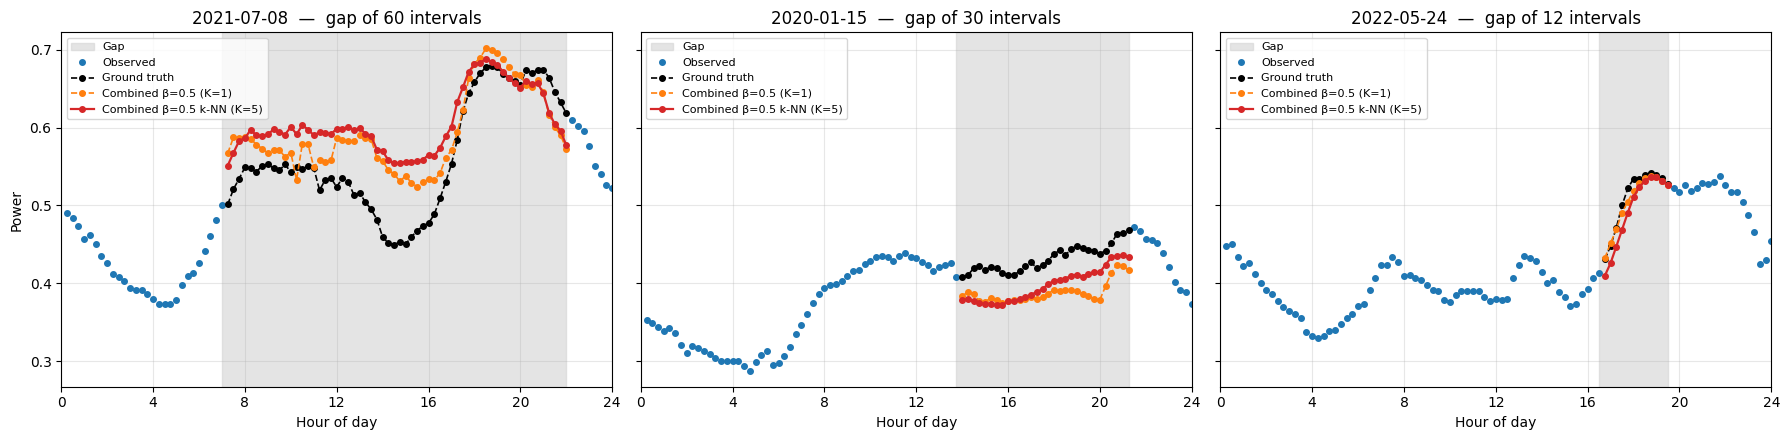

In [ ]:
GAP_LENGTHS_TO_PLOT = [60, 30, 12]

gap_lengths = {idx: end - start + 1 for idx, (start, end) in gaps.items()}
available   = sorted(set(gap_lengths.values()))

chosen = []
for target in GAP_LENGTHS_TO_PLOT:
    length = target if target in available else min(available, key=lambda L: abs(L - target))
    cands  = [idx for idx, L in gap_lengths.items() if L == length]
    pick   = int(np.random.default_rng(0).choice(cands))
    chosen.append((pick, length))

print(f"Available gap lengths: {available}")
print(f"β = {BETA_COMBINED}, λ = {LAMBDA_COMBINED}, K = {K_COMBINED}")

hours = (np.arange(N) + 1) * (24 / N)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for ax, (idx, length) in zip(axes, chosen):
    start, end = gaps[idx]
    date_str   = str(df_gaped.loc[idx, "Date"])
    shade_l, shade_r = start * (24 / N), (end + 1) * (24 / N)

    obs_mask = np.ones(N, dtype=bool); obs_mask[start:end + 1] = False

    truth = df_complete.loc[idx, time_cols].values.astype(float)
    k1    = df_combined_k1.loc[idx, time_cols].values.astype(float)
    knn   = df_combined_knn.loc[idx, time_cols].values.astype(float)

    ax.axvspan(shade_l, shade_r, color="lightgray", alpha=0.6, label="Gap")
    ax.plot(hours[obs_mask], truth[obs_mask], "o", color="tab:blue", markersize=4, label="Observed")
    ax.plot(hours[~obs_mask], truth[~obs_mask], "o--", color="black", markersize=4, linewidth=1.2, label="Ground truth")
    ax.plot(hours[~obs_mask], k1[~obs_mask], "o--", color="tab:orange", markersize=4, linewidth=1.2, label=f"Combined β={BETA_COMBINED} (K=1)")
    ax.plot(hours[~obs_mask], knn[~obs_mask], "o-",  color="tab:red",    markersize=4, linewidth=1.6, label=f"Combined β={BETA_COMBINED} k-NN (K={K_COMBINED})")

    ax.set_xlim(0, 24); ax.set_xticks([0, 4, 8, 12, 16, 20, 24])
    ax.set_xlabel("Hour of day")
    ax.set_title(f"{date_str}  —  gap of {length} intervals")
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)

axes[0].set_ylabel("Power")
plt.tight_layout()
plt.show()

## 7. Evaluation

Each imputation method produces a reconstructed series `phys_*.csv` or `trad_*.csv` with the same shape as `df_gaped.csv`. Because `df_gaped.csv` retains the NaN mask and `df_complete.csv` retains the ground truth, the reference values inside each gap are obtained directly by comparing the two:

$$
\text{gap positions} \;=\; \{t : \texttt{df\_gaped}_{i,t} \text{ is NaN}\}, \qquad
\text{reference}_{i,t} \;=\; \texttt{df\_complete}_{i,t}.
$$

No additional metadata column is needed. The comparison is valid as long as every imputed file uses the same gap positions, which is guaranteed because all methods were applied to the same `df_gaped.csv`.

Two metrics are computed per gapped day:

- **RMSE** — point-wise accuracy inside the gap,
$$
\text{RMSE}_i = \sqrt{\frac{1}{|\mathcal{I}_i|} \sum_{t \in \mathcal{I}_i} (y_{i,t} - \hat{y}_{i,t})^2},
$$
- **$E_{\text{diff}}$** — absolute difference in the energy accumulated inside the gap,
$$
E_{\text{diff},i} = \left| \sum_{t \in \mathcal{I}_i} y_{i,t} - \sum_{t \in \mathcal{I}_i} \hat{y}_{i,t} \right|.
$$

Since the imputed files differ from `df_complete.csv` only inside the gaps, computing $E_{\text{diff}}$ over the gap is equivalent to computing it over the whole day, with the advantage of not adding the (constant) energy of the observed intervals to every method.

In [ ]:
# --- input files ----------------------------------------------------------
METHOD_FILES = {
    "Linear"           : "trad_linear.csv",
    "Global avg"       : "trad_global_average.csv",
    "Avg point"        : "trad_average_point.csv",
    "Euclidean K=1"    : "phys_euclidean.csv",
    "Euclidean k-NN"   : "phys_euclidean_knn.csv",
    "DANLI λ=0"        : "phys_danli_l0.csv",
    "DANLI λ=1"        : "phys_danli_l1.csv",
    "DANLI λ=0 k-NN"   : "phys_danli_l0_knn.csv",
    "DANLI λ=1 k-NN"   : "phys_danli_l1_knn.csv",
    "Combined K=1"     : "phys_combined_k1.csv",
    "Combined k-NN"    : "phys_combined_knn.csv",
}

# --- ground truth and gap mask -------------------------------------------
df_gaped    = pd.read_csv("df_gaped.csv")
df_complete = pd.read_csv("df_complete.csv")

time_cols = [c for c in df_gaped.columns if ":" in str(c) and str(c)[0].isdigit()]
N = len(time_cols)

gaps = {}
for idx in df_gaped.index:
    is_nan = df_gaped.loc[idx, time_cols].isna().values
    if is_nan.any():
        pos = np.where(is_nan)[0]
        gaps[idx] = (int(pos.min()), int(pos.max()))

print(f"Gapped days: {len(gaps)}")

# --- compute per-day metrics for each method -----------------------------
def rmse_day(truth, pred):
    return float(np.sqrt(np.mean((truth - pred) ** 2)))

def ediff_day(truth, pred):
    return float(abs(truth.sum() - pred.sum()))

records = []
for method, path in METHOD_FILES.items():
    try:
        df_imp = pd.read_csv(path)
    except FileNotFoundError:
        print(f"  [skip] {method}: '{path}' not found")
        continue

    for idx, (start, end) in gaps.items():
        truth   = df_complete.loc[idx, time_cols[start:end + 1]].values.astype(float)
        imputed = df_imp.loc[idx, time_cols[start:end + 1]].values.astype(float)
        records.append({
            "method"     : method,
            "day_idx"    : idx,
            "gap_length" : end - start + 1,
            "rmse"       : rmse_day(truth, imputed),
            "e_diff"     : ediff_day(truth, imputed),
        })

df_metrics = pd.DataFrame(records)
print(f"Total rows : {len(df_metrics):,}")
print(f"Methods    : {df_metrics['method'].nunique()}")
df_metrics.head()

Gapped days: 2859
Total rows : 31,449
Methods    : 11


,method,day_idx,gap_length,rmse,e_diff
0,Linear,5,1,0.0026,0.0026
1,Linear,7,21,0.0302,0.5463
2,Linear,8,93,0.0823,3.2066
3,Linear,9,56,0.0443,0.5797
4,Linear,12,41,0.0461,0.8040


In [ ]:
summary = (
    df_metrics
    .groupby("method")
    .agg(
        rmse_mean  = ("rmse",   "mean"),
        rmse_std   = ("rmse",   "std"),
        ediff_mean = ("e_diff", "mean"),
        ediff_std  = ("e_diff", "std"),
        n_days     = ("rmse",   "count"),
    )
    .sort_values("ediff_mean")
    .reset_index()
)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
summary

,method,rmse_mean,rmse_std,ediff_mean,ediff_std,n_days
0,Euclidean k-NN,0.0316,0.0225,1.0524,1.3121,2859
1,Combined k-NN,0.0330,0.0233,1.1033,1.3539,2859
2,Euclidean K=1,0.0385,0.0272,1.2582,1.6172,2859
3,DANLI λ=0 k-NN,0.0409,0.0281,1.3360,1.5295,2859
4,Combined K=1,0.0408,0.0288,1.3517,1.7216,2859
5,DANLI λ=0,0.0507,0.0346,1.6502,1.9026,2859
6,Linear,0.0522,0.0331,1.6978,1.9835,2859
7,Avg point,0.0691,0.0435,2.6363,2.7710,2859
8,Global avg,0.0881,0.0460,2.7943,2.8479,2859
9,DANLI λ=1 k-NN,0.0814,0.0513,3.0911,2.9412,2859


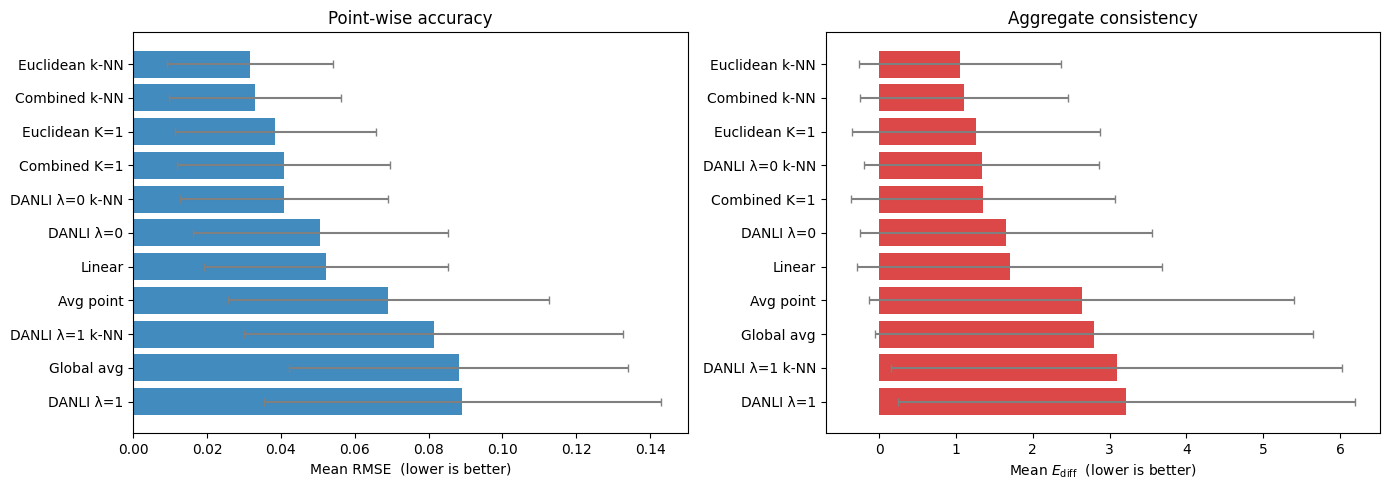

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_rmse  = summary.sort_values("rmse_mean")
order_ediff = summary.sort_values("ediff_mean")

axes[0].barh(order_rmse["method"],  order_rmse["rmse_mean"],
             xerr=order_rmse["rmse_std"],
             color="tab:blue", alpha=0.85, ecolor="gray", capsize=3)
axes[0].set_xlabel("Mean RMSE  (lower is better)")
axes[0].set_title("Point-wise accuracy")
axes[0].invert_yaxis()

axes[1].barh(order_ediff["method"], order_ediff["ediff_mean"],
             xerr=order_ediff["ediff_std"],
             color="tab:red", alpha=0.85, ecolor="gray", capsize=3)
axes[1].set_xlabel("Mean $E_{\\mathrm{diff}}$  (lower is better)")
axes[1].set_title("Aggregate consistency")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

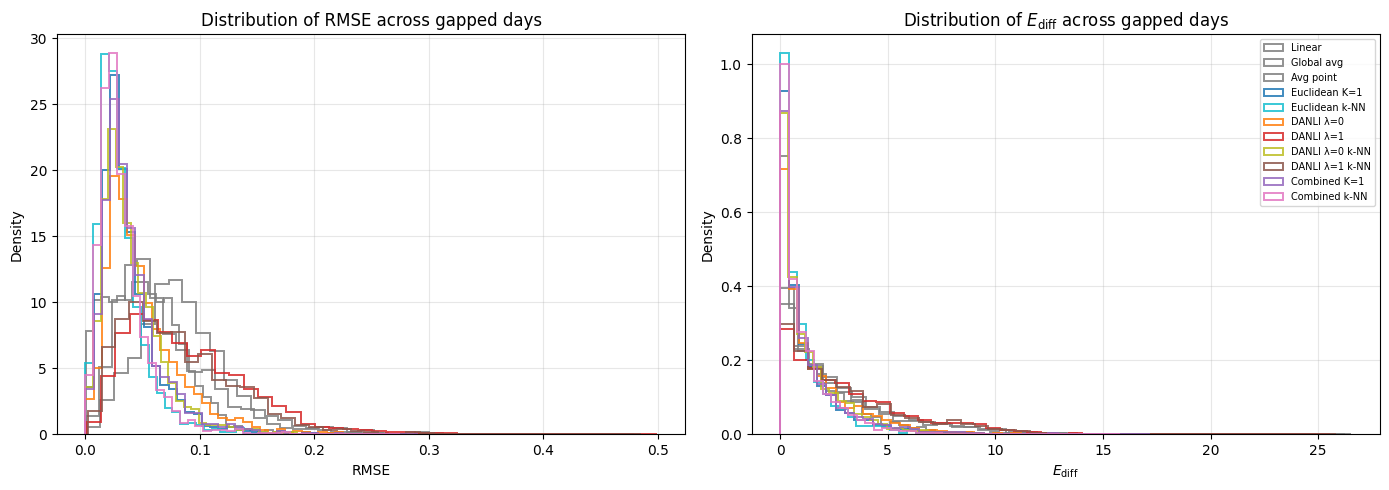

In [ ]:
FAMILY_COLOR = {
    "Linear"         : "tab:gray",
    "Global avg"     : "tab:gray",
    "Avg point"      : "tab:gray",
    "Euclidean K=1"  : "tab:blue",
    "Euclidean k-NN" : "tab:cyan",
    "DANLI λ=0"      : "tab:orange",
    "DANLI λ=1"      : "tab:red",
    "DANLI λ=0 k-NN" : "tab:olive",
    "DANLI λ=1 k-NN" : "tab:brown",
    "Combined K=1"   : "tab:purple",
    "Combined k-NN"  : "tab:pink",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric, ax, xlabel in [
    ("rmse",   axes[0], "RMSE"),
    ("e_diff", axes[1], "$E_{\\mathrm{diff}}$"),
]:
    for method in df_metrics["method"].unique():
        values = df_metrics.loc[df_metrics["method"] == method, metric].values
        ax.hist(values, bins=40, histtype="step", density=True,
                linewidth=1.4, alpha=0.85,
                color=FAMILY_COLOR.get(method, "black"),
                label=method)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.set_title(f"Distribution of {xlabel} across gapped days")
    ax.grid(alpha=0.3)

axes[1].legend(loc="upper right", fontsize=7, ncol=1)
plt.tight_layout()
plt.show()

### 8 Paired comparison of methods

The distributions in the previous section are skewed, and the observations are paired: every method imputes the same gapped days. Comparing means would discard the pairing and would misrepresent the central tendency. This section adopts a paired, non-parametric perspective:

- **Wilcoxon signed-rank test** on the per-day differences, with Holm–Bonferroni correction for multiple comparisons. Tests whether the difference between two methods is systematic or consistent with noise.
- **Paired dominance** $= P(A < B) - P(A > B)$, the proportion of days on which method A produces a lower error than method B minus the reverse proportion. It is the effect size associated with the Wilcoxon test, and ranges from $-1$ (A always worse) to $+1$ (A always better). Thresholds: $|r| < 0.1$ negligible, $0.1$–$0.3$ small, $0.3$–$0.5$ medium, $\geq 0.5$ large.
- **Bootstrap CI of the median difference**, providing the magnitude of the difference on the original scale of the metric.

The analysis is performed twice, once per metric, each time comparing every method against the best method for that metric.

In [ ]:
from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

def paired_dominance(a, b):
    """P(a < b) - P(a > b). Positive = a tends to be lower (better, since lower is better)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(np.mean(a < b) - np.mean(a > b))

def bootstrap_median_diff(a, b, n_boot=2000, alpha=0.05, seed=0):
    rng = np.random.default_rng(seed)
    diffs = np.asarray(a) - np.asarray(b)
    medians = np.array([np.median(rng.choice(diffs, len(diffs), replace=True))
                        for _ in range(n_boot)])
    lo, hi = np.quantile(medians, [alpha / 2, 1 - alpha / 2])
    return float(np.median(diffs)), float(lo), float(hi)

def compare_vs_reference(df_metrics, metric, reference_method):
    pivot = df_metrics.pivot(index="day_idx", columns="method", values=metric).dropna()
    ref = pivot[reference_method].values
    rows = []
    for method in pivot.columns:
        if method == reference_method:
            continue
        m = pivot[method].values
        try:
            _, pval = wilcoxon(m, ref)
        except ValueError:
            pval = 1.0
        med, lo, hi = bootstrap_median_diff(m, ref)
        rows.append({
            "method"     : method,
            "median_diff": med,
            "ci_lo"      : lo,
            "ci_hi"      : hi,
            "p_raw"      : pval,
            "dominance"  : paired_dominance(m, ref),
        })
    out = pd.DataFrame(rows).sort_values("p_raw").reset_index(drop=True)
    # Holm–Bonferroni
    k = len(out)
    out["p_holm"] = [(k - i) * out.loc[i, "p_raw"] for i in range(k)]
    out["p_holm"] = out["p_holm"].clip(upper=1.0)
    out["significant"] = out["p_holm"] < 0.05
    return out

best_rmse  = df_metrics.groupby("method")["rmse"].median().idxmin()
best_ediff = df_metrics.groupby("method")["e_diff"].median().idxmin()

print(f"Reference for RMSE   : {best_rmse}")
print(f"Reference for E_diff : {best_ediff}")

cmp_rmse  = compare_vs_reference(df_metrics, "rmse",   best_rmse)
cmp_ediff = compare_vs_reference(df_metrics, "e_diff", best_ediff)

print("\n— RMSE (reference = best) —")
print(cmp_rmse.to_string(index=False))
print("\n— E_diff (reference = best) —")
print(cmp_ediff.to_string(index=False))

Reference for RMSE   : Euclidean k-NN
Reference for E_diff : Combined k-NN

— RMSE (reference = best) —
        method  median_diff  ci_lo  ci_hi  p_raw  dominance  p_holm  significant
     Avg point       0.0294 0.0275 0.0305 0.0000    -0.7342  0.0000         True
     DANLI λ=1       0.0499 0.0476 0.0520 0.0000    -0.7740  0.0000         True
DANLI λ=1 k-NN       0.0430 0.0402 0.0452 0.0000    -0.7083  0.0000         True
    Global avg       0.0510 0.0496 0.0524 0.0000    -0.8881  0.0000         True
     DANLI λ=0       0.0130 0.0119 0.0140 0.0000    -0.5425  0.0000         True
        Linear       0.0179 0.0162 0.0195 0.0000    -0.4900  0.0000         True
  Combined K=1       0.0067 0.0060 0.0073 0.0000    -0.4131  0.0000         True
DANLI λ=0 k-NN       0.0051 0.0045 0.0057 0.0000    -0.3652  0.0000         True
 Euclidean K=1       0.0049 0.0044 0.0056 0.0000    -0.3358  0.0000         True
 Combined k-NN       0.0005 0.0002 0.0007 0.0000    -0.1133  0.0000         True

— E_

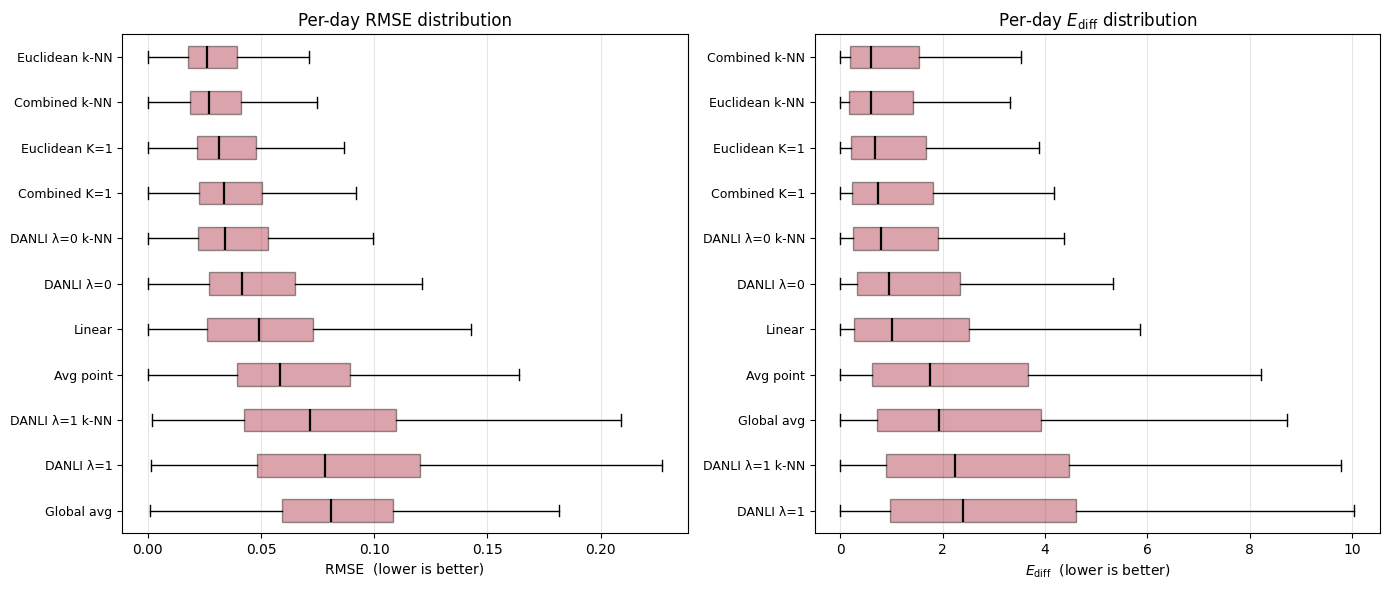

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metric, title in zip(axes, ["rmse", "e_diff"], ["RMSE", "$E_{\\mathrm{diff}}$"]):
    order = df_metrics.groupby("method")[metric].median().sort_values().index
    data  = [df_metrics.loc[df_metrics["method"] == m, metric].values for m in order]

    ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#A6192E", alpha=0.4),
               medianprops=dict(color="black", linewidth=1.6))
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels(order, fontsize=9)
    ax.set_xlabel(f"{title}  (lower is better)")
    ax.set_title(f"Per-day {title} distribution")
    ax.grid(alpha=0.3, axis="x")
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

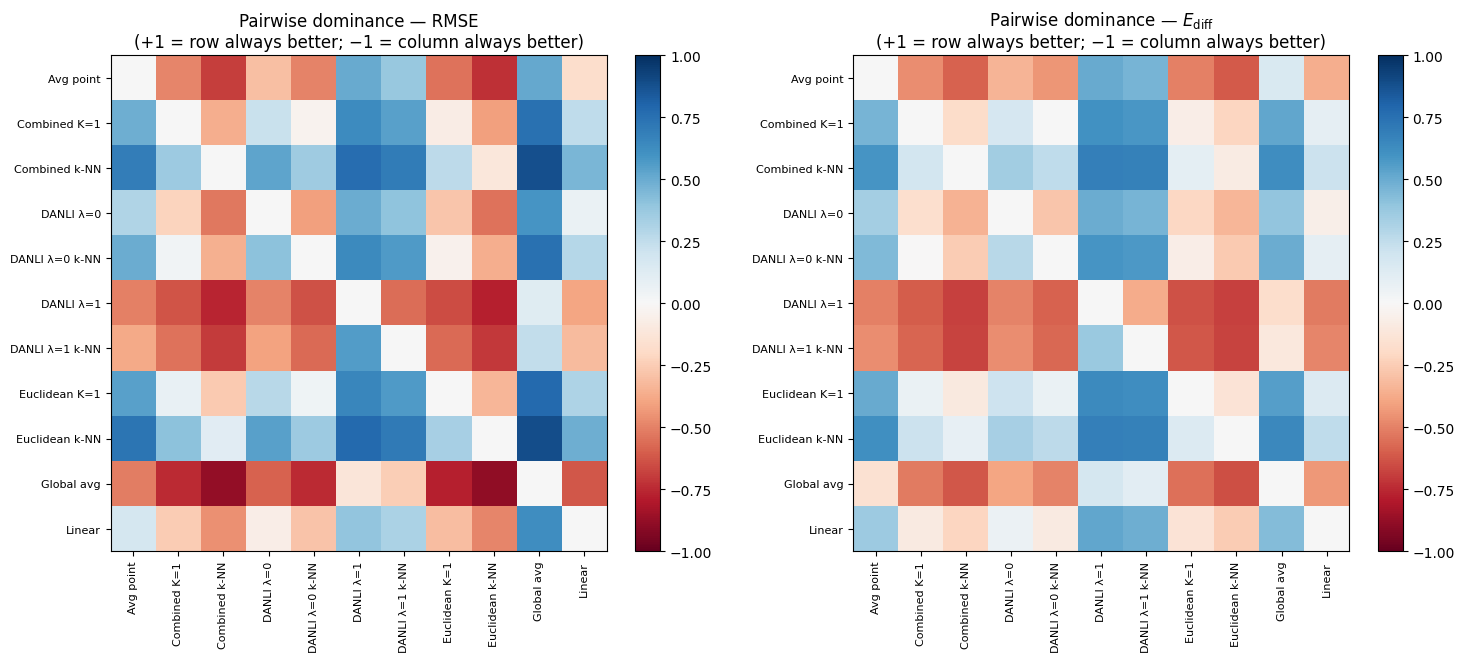

In [ ]:
methods = sorted(df_metrics["method"].unique())
n = len(methods)

delta_rmse  = np.zeros((n, n))
delta_ediff = np.zeros((n, n))

for i, m1 in enumerate(methods):
    for j, m2 in enumerate(methods):
        if i == j:
            continue
        for metric, target in [("rmse", delta_rmse), ("e_diff", delta_ediff)]:
            a = df_metrics.loc[df_metrics["method"] == m1].set_index("day_idx")[metric]
            b = df_metrics.loc[df_metrics["method"] == m2].set_index("day_idx")[metric]
            common = a.index.intersection(b.index)
            target[i, j] = paired_dominance(a.loc[common].values, b.loc[common].values)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, delta, title in zip(axes, [delta_rmse, delta_ediff], ["RMSE", "$E_{\\mathrm{diff}}$"]):
    im = ax.imshow(delta, cmap="RdBu", vmin=-1, vmax=1)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(methods, rotation=90, fontsize=8)
    ax.set_yticklabels(methods, fontsize=8)
    ax.set_title(f"Pairwise dominance — {title}\n"
                 f"(+1 = row always better; −1 = column always better)")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

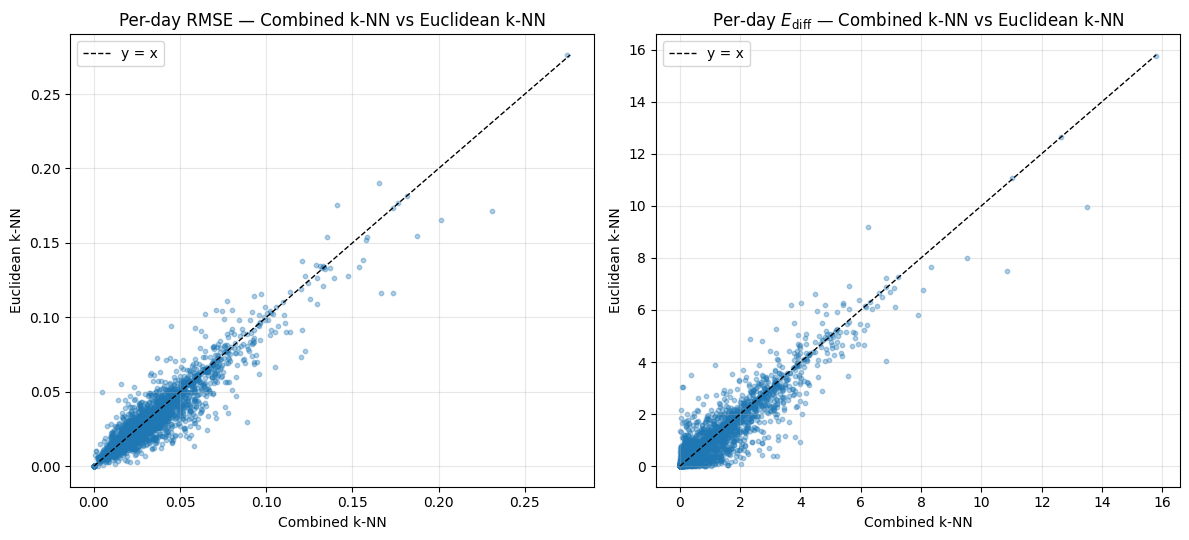

In [ ]:
METHOD_A = "Combined k-NN" #"DANLI λ=0"
METHOD_B = "Euclidean k-NN"   # typically the best per metric; adjust to match your results

pivot_rmse  = df_metrics.pivot(index="day_idx", columns="method", values="rmse")
pivot_ediff = df_metrics.pivot(index="day_idx", columns="method", values="e_diff")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, pivot, title in zip(axes, [pivot_rmse, pivot_ediff], ["RMSE", "$E_{\\mathrm{diff}}$"]):
    x = pivot[METHOD_A].values
    y = pivot[METHOD_B].values
    ax.scatter(x, y, alpha=0.35, s=10)
    lim = max(np.nanmax(x), np.nanmax(y))
    ax.plot([0, lim], [0, lim], "k--", linewidth=1, label="y = x")
    ax.set_xlabel(METHOD_A)
    ax.set_ylabel(METHOD_B)
    ax.set_title(f"Per-day {title} — {METHOD_A} vs {METHOD_B}")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### 8.1 Interpretation

The results support two complementary readings that should be presented together.

**Statistically distinct, practically similar.** The Wilcoxon tests indicate whether each method's median error differs systematically from the best method. A small $p$-value (after Holm–Bonferroni) only says the direction of the difference is consistent, not that the difference is large. The paired dominance quantifies magnitude: values below $0.1$ in absolute value correspond to negligible practical differences; values between $0.1$ and $0.3$ to small ones. When the best method and the proposed method differ by a small dominance on a metric, the correct conclusion is that the two methods produce comparable reconstructions despite the statistical significance.

**Different objectives, not competing objectives.** The Euclidean criterion minimizes point-wise discrepancy over the observed intervals. The DANLI criterion operates in the cumulative space and, with $\lambda = 1$, penalizes departures from the mean daily energy. A method that outperforms on RMSE does so by construction of its objective; a method that outperforms on $E_{\text{diff}}$ does so for the same reason. The comparison should therefore not be reduced to a single "winner". The appropriate question is which objective is relevant for the downstream application: point-wise fidelity matters when the reconstructed profile feeds a model that operates at the interval level; aggregate consistency matters when the total daily energy has operational, economic, or physical significance.

In this dataset, the per-day scatter confirms the picture: the points cluster near the diagonal on both metrics, which indicates that the two methods agree on most days, with the disagreements concentrated on the days where the two criteria make different choices among plausible candidates. Those days are the ones the discussion should highlight.

In [ ]:
def verdict_from_dominance(r, significant):
    if not significant:
        return "no reliable difference"
    a = abs(r)
    if a < 0.1:
        return "real but negligible"
    if a < 0.3:
        return "small difference"
    if a < 0.5:
        return "medium difference"
    return "large difference"

def summarize(cmp, metric_name, reference):
    cmp = cmp.copy()
    cmp["verdict"] = [verdict_from_dominance(r, s)
                      for r, s in zip(cmp["dominance"], cmp["significant"])]
    cmp["worse_than_ref"] = cmp["dominance"] < 0

    print(f"\n{'=' * 72}")
    print(f"METRIC: {metric_name}   (reference = {reference})")
    print(f"{'=' * 72}")

    groups = {
        "TIED with reference (|r| < 0.1)":        cmp[cmp["dominance"].abs() < 0.1],
        "SMALL difference (0.1 ≤ |r| < 0.3)":     cmp[(cmp["dominance"].abs() >= 0.1) & (cmp["dominance"].abs() < 0.3)],
        "MEDIUM difference (0.3 ≤ |r| < 0.5)":    cmp[(cmp["dominance"].abs() >= 0.3) & (cmp["dominance"].abs() < 0.5)],
        "LARGE difference (|r| ≥ 0.5)":           cmp[cmp["dominance"].abs() >= 0.5],
    }
    for label, subset in groups.items():
        if len(subset) == 0:
            continue
        print(f"\n  {label}")
        for _, row in subset.sort_values("dominance", ascending=False).iterrows():
            direction = "worse" if row["worse_than_ref"] else "better"
            print(f"    • {row['method']:<22}  "
                  f"{direction:<7}  r = {row['dominance']:+.3f}  "
                  f"Δ median = {row['median_diff']:+.4f}  "
                  f"CI [{row['ci_lo']:+.4f}, {row['ci_hi']:+.4f}]")

summarize(cmp_rmse,  "RMSE",   best_rmse)
summarize(cmp_ediff, "E_diff", best_ediff)


METRIC: RMSE   (reference = Euclidean k-NN)

  SMALL difference (0.1 ≤ |r| < 0.3)
    • Combined k-NN           worse    r = -0.113  Δ median = +0.0005  CI [+0.0002, +0.0007]

  MEDIUM difference (0.3 ≤ |r| < 0.5)
    • Euclidean K=1           worse    r = -0.336  Δ median = +0.0049  CI [+0.0044, +0.0056]
    • DANLI λ=0 k-NN          worse    r = -0.365  Δ median = +0.0051  CI [+0.0045, +0.0057]
    • Combined K=1            worse    r = -0.413  Δ median = +0.0067  CI [+0.0060, +0.0073]
    • Linear                  worse    r = -0.490  Δ median = +0.0179  CI [+0.0162, +0.0195]

  LARGE difference (|r| ≥ 0.5)
    • DANLI λ=0               worse    r = -0.542  Δ median = +0.0130  CI [+0.0119, +0.0140]
    • DANLI λ=1 k-NN          worse    r = -0.708  Δ median = +0.0430  CI [+0.0402, +0.0452]
    • Avg point               worse    r = -0.734  Δ median = +0.0294  CI [+0.0275, +0.0305]
    • DANLI λ=1               worse    r = -0.774  Δ median = +0.0499  CI [+0.0476, +0.0520]
    • Glo

In [ ]:
def _names(df, r_max=None, r_min=None):
    """Filter methods by dominance range; return as sorted list of strings."""
    s = df.copy()
    if r_max is not None:
        s = s[s["dominance"].abs() < r_max]
    if r_min is not None:
        s = s[s["dominance"].abs() >= r_min]
    return list(s.sort_values("dominance", ascending=False)["method"])

def _bullets(names):
    return "\n".join(f"    – {m}" for m in names) if names else "    – (none)"

def natural_summary(cmp, metric_name, reference, best_value):
    tied  = _names(cmp, r_max=0.1)
    small = _names(cmp, r_min=0.1, r_max=0.3)
    med   = _names(cmp, r_min=0.3, r_max=0.5)
    large = _names(cmp, r_min=0.5)

    better = cmp[cmp["dominance"] > 0]

    print(f"\n{'─' * 72}")
    print(f"  {metric_name}")
    print(f"{'─' * 72}")
    print(f"  Best method (reference) : {reference}")
    print(f"  Median {metric_name:<15}: {best_value:.6f}")
    print()

    if len(better) > 0:
        print(f"  Methods that outperform the reference (|r| ≥ 0.1):")
        print(_bullets([f"{m} (r={cmp.loc[cmp['method']==m,'dominance'].iloc[0]:+.3f})"
                        for m in better["method"]]))
    else:
        print(f"  No method outperforms the reference on {metric_name}.")

    print()
    print(f"  Statistically tied with the reference (|r| < 0.1, negligible):")
    print(_bullets(tied))

    if small:
        print()
        print(f"  Small but real difference (0.1 ≤ |r| < 0.3):")
        print(_bullets(small))

    if med:
        print()
        print(f"  Medium difference (0.3 ≤ |r| < 0.5):")
        print(_bullets(med))

    if large:
        print()
        print(f"  Large difference (|r| ≥ 0.5) — clearly behind the reference:")
        print(_bullets(large))


print("\n" + "=" * 72)
print("  SUMMARY OF PAIRED COMPARISON")
print("=" * 72)

natural_summary(cmp_rmse,  "RMSE",   best_rmse,
                df_metrics.loc[df_metrics['method'] == best_rmse,  'rmse'].median())
natural_summary(cmp_ediff, "E_diff", best_ediff,
                df_metrics.loc[df_metrics['method'] == best_ediff, 'e_diff'].median())

# --- cross-metric observation --------------------------------------------
print("\n" + "─" * 72)
print("  Cross-metric reading")
print("─" * 72)

tied_rmse  = set(_names(cmp_rmse,  r_max=0.1))
tied_ediff = set(_names(cmp_ediff, r_max=0.1))
small_rmse  = set(_names(cmp_rmse,  r_min=0.1, r_max=0.3))
small_ediff = set(_names(cmp_ediff, r_min=0.1, r_max=0.3))

near_both = (tied_rmse | small_rmse) & (tied_ediff | small_ediff)
if near_both:
    print("  Methods that remain close to the best on BOTH metrics:")
    for m in sorted(near_both):
        r_r = cmp_rmse.loc[cmp_rmse['method'] == m, 'dominance'].iloc[0]
        r_e = cmp_ediff.loc[cmp_ediff['method'] == m, 'dominance'].iloc[0]
        print(f"    – {m:<22}  r_RMSE = {r_r:+.3f}   r_E_diff = {r_e:+.3f}")
else:
    print("  No single method is simultaneously close to the best on both metrics.")

print()
print("  Interpretation:")
print("  · 'Tied' means the median error differs by less than 0.1 of the")
print("    paired dominance, which corresponds to an effect size that is")
print("    negligible in practice.")
print("  · 'Small' means the direction is consistent (p < 0.05 after Holm)")
print("    but the magnitude is modest; the practical relevance depends on")
print("    the tolerance of the downstream application.")
print("  · 'Medium' and 'large' indicate a ranking that should be reported")
print("    as such, without further caveats.")


  SUMMARY OF PAIRED COMPARISON

────────────────────────────────────────────────────────────────────────
  RMSE
────────────────────────────────────────────────────────────────────────
  Best method (reference) : Euclidean k-NN
  Median RMSE           : 0.026116

  No method outperforms the reference on RMSE.

  Statistically tied with the reference (|r| < 0.1, negligible):
    – (none)

  Small but real difference (0.1 ≤ |r| < 0.3):
    – Combined k-NN

  Medium difference (0.3 ≤ |r| < 0.5):
    – Euclidean K=1
    – DANLI λ=0 k-NN
    – Combined K=1
    – Linear

  Large difference (|r| ≥ 0.5) — clearly behind the reference:
    – DANLI λ=0
    – DANLI λ=1 k-NN
    – Avg point
    – DANLI λ=1
    – Global avg

────────────────────────────────────────────────────────────────────────
  E_diff
────────────────────────────────────────────────────────────────────────
  Best method (reference) : Combined k-NN
  Median E_diff         : 0.601708

  Methods that outperform the reference (|r|

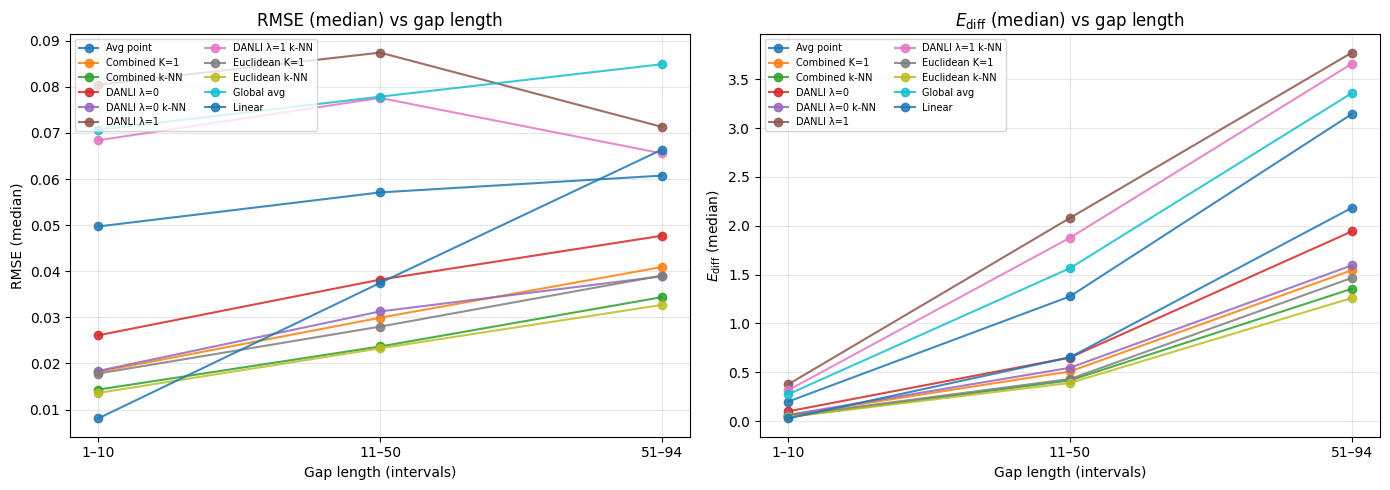

In [ ]:
df_metrics["gap_bin"] = pd.cut(
    df_metrics["gap_length"],
    bins=[0, 10, 50, 94],
    labels=["1–10", "11–50", "51–94"],
)

# Median per bin
strat = (
    df_metrics
    .groupby(["gap_bin", "method"], observed=True)
    .agg(rmse_med=("rmse", "median"), ediff_med=("e_diff", "median"))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes,
                             ["rmse_med", "ediff_med"],
                             ["RMSE (median)", "$E_{\\mathrm{diff}}$ (median)"]):
    for m in strat["method"].unique():
        sub = strat[strat["method"] == m]
        ax.plot(sub["gap_bin"], sub[metric], "o-", label=m, alpha=0.85)
    ax.set_xlabel("Gap length (intervals)")
    ax.set_ylabel(title)
    ax.set_title(f"{title} vs gap length")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper left", ncol=2)

plt.tight_layout()
plt.show()

### 9 Summary of the comparison

The paired analysis was run at a 20% and 40% fraction of missing days, and the pattern of results is consistent across both. Three observations summarize the comparison.

**The combined criterion matches the best baseline.** Euclidean k-NN is the reference method for both RMSE and $E_\text{diff}$ in both runs. No method improves on it by a margin that would be distinguishable in practice. The combined criterion ($\beta = 0.5$, $\lambda = 1$) is the only method that remains close to the reference on **both** metrics simultaneously: its paired dominance falls within the small-difference band on each, and the bootstrap median difference is negligible on the normalized scale. This is the central finding: the cumulative-energy perspective can be preserved without a measurable performance cost when it is combined with the point-wise criterion through normalized distances.

**The isolated $\lambda = 1$ regularization over-regularizes.** DANLI with $\lambda = 1$ applied on its own shows a systematically larger deviation from the reference. The mechanics explain why. For long gaps, the boundary observations provide little information, the forward and backward cumulative discrepancies are small relative to the total-energy term, and the $\lambda = 1$ penalty dominates candidate selection. The reconstruction is then pulled toward the weekday mean, which is a reasonable prior but does not capture day-specific departures. The combined criterion corrects this by normalizing each distance component before mixing, so that neither the boundary term nor the total-energy term overwhelms the other. The result is a criterion that inherits the benefits of both perspectives without the over-regularization of either.

**Traditional methods fall in the medium-to-large difference range.** Global mean, linear interpolation, and average point are systematically behind the reference on both metrics. This is expected: they optimize simple statistics or local continuity, and neither of these accounts for the shape of the specific day being reconstructed. Their role in the comparison is to establish that the improvement of the similarity-based methods is not trivial.

The comparison therefore does not identify a single winner. It identifies the combined criterion as the formulation that preserves the cumulative principle without a measurable cost, and it clarifies the regime in which the isolated $\lambda = 1$ penalty is beneficial and the regime in which it over-regularizes. This is a design insight rather than a ranking outcome: the Euclidean and cumulative criteria optimize different objectives, and the comparison maps the trade-off between them rather than declaring one superior to the other.